# 🛍️ Omnichannel Customer Intelligence Platform
## Fashion & Retail — Complete ML Workflow with Explainable AI

---

[![Python](https://img.shields.io/badge/Python-3.10-blue?style=flat-square&logo=python)](https://python.org)
[![XGBoost](https://img.shields.io/badge/XGBoost-2.0-orange?style=flat-square)](https://xgboost.readthedocs.io)
[![SHAP](https://img.shields.io/badge/SHAP-0.44-purple?style=flat-square)](https://shap.readthedocs.io)
[![MLflow](https://img.shields.io/badge/MLflow-2.10-blue?style=flat-square&logo=mlflow)](https://mlflow.org)

---

### 📋 About this Notebook

Senior **Machine Learning** notebook applied to omnichannel fashion retail.  
Each section has **two explanation layers** — for non-technical readers and for engineers.

| 🏷️ For the business reader | ⚙️ For the engineer |
|---------------------------|---------------------|
| Plain-language intuition | Implementation, formulas, design decisions |
| Real-world analogies | Complexity, tradeoffs, alternatives |

---

### 🗺️ Pipeline Overview

```
Raw Data (Bronze)
      ↓  dedup · join · label encoding · 9 derived features
Unified Profile (Silver)
      ↓  CLV target engineering
Analytical Tables (Gold)
      ↓
  ┌──────────────┬─────────────────┬──────────────────┐
  │   Churn      │      CLV        │   Segmentation   │
  │ XGBoost Cls  │ XGBoost Reg     │   KMeans         │
  │ AUC = 0.795  │ R² = 0.990      │   K opt (sil)    │
  └──────┬───────┴────────┬────────┴─────────┬────────┘
         │ SHAP XAI       │ SHAP XAI         │ Profiles
         ↓                ↓                  ↓
    A/B Testing  →  Executive Dashboard  →  MLflow Registry
```

| # | Section | Technique |
|---|---------|-----------|
| 0 | Setup & Installation | pip install + dark fashion theme |
| 1 | 🥉 Bronze Layer | Raw omnichannel data (8k customers · 35k transactions) |
| 2 | 🥈 Silver Layer | Cleaning · Aggregation · 9 derived features |
| 3 | 🥇 Gold Layer | ML-ready analytical tables |
| 4 | 🔴 Churn Prediction | XGBoost · ROC · PR · Confusion Matrix |
| 5 | 🔍 XAI Churn | SHAP global · Beeswarm · Dependence · Waterfall |
| 6 | 💰 CLV Prediction | XGBoost Regressor · Residuals · Tier analysis |
| 7 | 🔍 XAI CLV | SHAP importance · Dependence plot |
| 8 | 👥 Segmentation | KMeans · Silhouette · Cluster profiling |
| 9 | 🧪 A/B Testing | Z-test · Uplift Curve · Forest Plot IC 95% |
| 10 | 📊 Dashboard | Executive KPIs · Portfolio View · CRM actions |
| 11 | 📦 MLflow | Experiment tracking · Model registry |
| 12 | 📋 Final Report | Programmatic synthesis · Markdown export |


---
## ⚙️ Section 0 — Setup & Installation

> 🏷️ **For the business reader:** Like equipping a kitchen before cooking.  
> We install the tools (libraries) used throughout the project.

> ⚙️ **For the engineer:**
> | Library | Min version | Role |
> |---------|------------|------|
> | `xgboost` | ≥ 2.0 | Gradient boosting for churn and CLV |
> | `shap` | ≥ 0.44 | Shapley values for XAI |
> | `mlflow` | ≥ 2.10 | Experiment tracking & model registry |
> | `imbalanced-learn` | ≥ 0.12 | Utilities for imbalanced classes |
> | `plotly` | ≥ 5.18 | Interactive visualisations (optional) |


In [1]:
# ── Install dependencies (Google Colab)
import subprocess, sys

PACKAGES = [
    "xgboost>=2.0",
    "lightgbm>=4.3",
    "mlflow>=2.10",
    "shap>=0.44",
    "plotly>=5.18",
    "imbalanced-learn>=0.12",
]

print("📦 Installing dependencies...")
for pkg in PACKAGES:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], capture_output=True)
print("✅ All dependencies installed")

📦 Installing dependencies...
✅ All dependencies installed


In [2]:
# ── Imports and global configuration
import warnings; warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import random, os, json, joblib
from datetime import datetime, timedelta

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    precision_recall_curve, average_precision_score,
    mean_absolute_error, r2_score, mean_squared_error, silhouette_score,
)
from sklearn.cluster import KMeans
from xgboost import XGBClassifier, XGBRegressor
import shap
import mlflow, mlflow.sklearn, mlflow.xgboost
from scipy import stats as scipy_stats
from scipy.stats import binned_statistic

# ── Reproducibility
SEED = 42
np.random.seed(SEED); random.seed(SEED)

# ── Dark fashion theme
DARK_BG  = '#0a0a18'
PANEL_BG = '#0f0f22'
PAL = [
    '#7c3aed','#06b6d4','#f59e0b','#10b981','#ef4444',
    '#8b5cf6','#ec4899','#14b8a6','#f97316','#84cc16',
]
plt.rcParams.update({
    'figure.facecolor':  DARK_BG,  'axes.facecolor':    PANEL_BG,
    'axes.edgecolor':    '#2a2a4a','axes.labelcolor':   '#c8c8e8',
    'xtick.color':       '#8888bb','ytick.color':       '#8888bb',
    'text.color':        '#c8c8e8','grid.color':        '#1e1e38',
    'grid.linestyle':    '--',     'font.family':       'monospace',
    'font.size':          10,      'legend.framealpha':  0.30,
    'legend.edgecolor':  '#2a2a4a',
})

for d in ['data/bronze','data/silver','data/gold','reports','models']:
    os.makedirs(d, exist_ok=True)

print(f"✅ Setup complete")
print(f"   NumPy {np.__version__} · Pandas {pd.__version__}")
print(f"   XGBoost {__import__('xgboost').__version__} · SHAP {shap.__version__}")
print(f"   MLflow {mlflow.__version__} · Seed {SEED}")

✅ Setup complete
   NumPy 2.0.2 · Pandas 2.2.2
   XGBoost 3.2.0 · SHAP 0.51.0
   MLflow 3.12.0 · Seed 42


---
## 🥉 Section 1 — Bronze Layer: Raw Omnichannel Data

> 🏷️ **For the business reader:** The Bronze Layer is the company's raw archive —  
> data **exactly as it arrives from source systems**, unprocessed.  
> Two sources: customer profiles and purchase history.

> ⚙️ **For the engineer:**  
> Realistic simulation of two omnichannel data sources:
> - **Customers (8k):** behavioural profile + `churned` target via calibrated risk function
> - **Transactions (35k):** transactions with campaign metadata, seasonality, channel and discount
>
> **Churn target formula:**
> $$P(churn) = 0.45 \cdot \mathbb{1}[days > 180] + 0.20 \cdot \mathbb{1}[purchases < 3] + 0.15 \cdot \mathbb{1}[email < 0.05] + 0.10 \cdot \mathbb{1}[tickets > 3] + \varepsilon$$
> Calibrated rate: ~33-35% (realistic for fashion mid-market)


In [3]:
# ── Fashion domain constants
BRANDS = [
    'Zara','H&M','Mango','Uniqlo','Reserved',
    'Stradivarius','Pull&Bear','Bershka','Massimo Dutti','COS',
]
CATEGORIES = [
    'Tops','Dresses','Bottoms','Outerwear','Footwear',
    'Accessories','Underwear','Sportswear','Bags','Jewelry',
]
CHANNELS = [
    'ecommerce','mobile_app','physical_store',
    'instagram_shop','email_campaign','loyalty_program',
]
COUNTRIES  = ['Portugal','Spain','France','Germany','UK','Italy','Netherlands','Poland','Brazil','USA']
SEASONS    = ['SS23','FW23','SS24','FW24']

N_CUSTOMERS    = 8_000
N_TRANSACTIONS = 35_000
now = datetime.now()

print(f"✅ Domain constants loaded: {len(BRANDS)} brands · {len(CATEGORIES)} categories")
print(f"   {len(CHANNELS)} channels · {len(COUNTRIES)} countries · {len(SEASONS)} seasons")
print(f"   Generating: {N_CUSTOMERS:,} customers · {N_TRANSACTIONS:,} transactions")

✅ Domain constants loaded: 10 brands · 10 categories
   6 channels · 10 countries · 4 seasons
   Generating: 8,000 customers · 35,000 transactions


In [4]:
def generate_customers(n: int) -> pd.DataFrame:
    """
    Generate synthetic fashion customer profiles with calibrated churn target.

    Target engineering:
        P(churn) = sum(weights × risk indicators) + uniform noise

    Weights calibrated to reflect real abandonment behaviour in
    mid-market fashion retailers:
    - 0.45 × recency  (6+ months inactive = strong signal)
    - 0.20 × frequency (one-time buyers have high abandonment rate)
    - 0.15 × digital engagement (email as interest proxy)
    - 0.10 × dissatisfaction (support tickets as friction proxy)
    """
    df = pd.DataFrame({
        'customer_id':           [f'CUST_{i:05d}' for i in range(n)],
        'age':                    np.random.randint(18, 65, n),
        'gender':                 np.random.choice(['F','M','NB'], n, p=[0.62,0.33,0.05]),
        'country':                np.random.choice(COUNTRIES, n),
        'preferred_channel':      np.random.choice(CHANNELS, n),
        'loyalty_tier':           np.random.choice(
                                      ['Bronze','Silver','Gold','Platinum'], n,
                                      p=[0.50,0.28,0.15,0.07]),
        'registration_date':      [(now - timedelta(days=random.randint(30,1095)))
                                   .strftime('%Y-%m-%d') for _ in range(n)],
        'last_purchase_days_ago': np.random.randint(1, 365, n),
        'total_purchases':        np.random.randint(1, 80, n),
        'avg_order_value':        np.round(np.random.lognormal(4.0, 0.8, n), 2),
        'email_open_rate':        np.round(np.random.beta(2, 5, n), 3),
        'app_sessions_30d':       np.random.randint(0, 60, n),
        'returns_rate':           np.round(np.random.beta(1.5, 8, n), 3),
        'support_tickets_12m':    np.random.randint(0, 8, n),
        'nps_score':              np.random.choice(range(0, 11), n).astype(float),
        'omnichannel_flag':       np.random.choice([0, 1], n, p=[0.45, 0.55]),
        'preferred_brand':        np.random.choice(BRANDS, n),
        'preferred_category':     np.random.choice(CATEGORIES, n),
    })
    df['total_revenue'] = np.round(df['total_purchases'] * df['avg_order_value'], 2)

    churn_prob = (
        (df['last_purchase_days_ago'] > 180).astype(float) * 0.45 +
        (df['total_purchases'] < 3).astype(float)           * 0.20 +
        (df['email_open_rate'] < 0.05).astype(float)        * 0.15 +
        (df['support_tickets_12m'] > 3).astype(float)       * 0.10 +
        np.random.uniform(0, 0.10, n)
    )
    df['churned'] = (np.random.uniform(size=n) < np.clip(churn_prob, 0, 1)).astype(int)
    return df


def generate_transactions(customers_df: pd.DataFrame, n: int) -> pd.DataFrame:
    """Generate omnichannel transactions with fashion seasonality and discount policies."""
    cust_ids = customers_df['customer_id'].values
    rows = []
    for _ in range(n):
        days_ago = random.randint(1, 730)
        qty      = random.randint(1, 5)
        price    = round(random.uniform(9.99, 299.99), 2)
        discount = round(random.uniform(0, 0.40), 2)
        rows.append({
            'transaction_id':   f'TXN_{random.randint(100_000, 999_999)}',
            'customer_id':      random.choice(cust_ids),
            'date':             (now - timedelta(days=days_ago)).strftime('%Y-%m-%d'),
            'season':           random.choice(SEASONS),
            'brand':            random.choice(BRANDS),
            'category':         random.choice(CATEGORIES),
            'channel':          random.choice(CHANNELS),
            'quantity':         qty,
            'unit_price':       price,
            'discount_applied': discount,
            'total_amount':     round(qty * price * (1 - discount), 2),
            'returned':         random.choice([0, 0, 0, 0, 1]),
        })
    return pd.DataFrame(rows)

In [5]:
# ── Generate and save Bronze Layer
print("🏗️  Generating Bronze Layer...")
customers_bronze    = generate_customers(N_CUSTOMERS)
transactions_bronze = generate_transactions(customers_bronze, N_TRANSACTIONS)

customers_bronze.to_csv('data/bronze/customers_raw.csv', index=False)
transactions_bronze.to_csv('data/bronze/transactions_raw.csv', index=False)

churn_rate = customers_bronze['churned'].mean()
print(f"\n✅ Bronze Layer created:")
print(f"   customers_raw.csv    → {len(customers_bronze):,} rows × {customers_bronze.shape[1]} cols")
print(f"   transactions_raw.csv → {len(transactions_bronze):,} rows × {transactions_bronze.shape[1]} cols")
print(f"\n📊 Bronze KPIs:")
print(f"   Churn rate    : {churn_rate:.1%}  ({customers_bronze['churned'].sum():,} positives)")
print(f"   Avg revenue   : €{customers_bronze['total_revenue'].mean():,.2f}")
print(f"   Avg order val : €{customers_bronze['avg_order_value'].mean():,.2f}")
print(f"   Avg NPS       : {customers_bronze['nps_score'].mean():.1f} / 10")
print(f"\n📋 Sample (5 customers):")
display(customers_bronze[
    ['customer_id','age','gender','loyalty_tier',
     'last_purchase_days_ago','total_revenue','churned']
].head())

🏗️  Generating Bronze Layer...

✅ Bronze Layer created:
   customers_raw.csv    → 8,000 rows × 20 cols
   transactions_raw.csv → 35,000 rows × 12 cols

📊 Bronze KPIs:
   Churn rate    : 33.7%  (2,698 positives)
   Avg revenue   : €3,031.45
   Avg order val : €76.15
   Avg NPS       : 5.0 / 10

📋 Sample (5 customers):


,customer_id,age,gender,loyalty_tier,last_purchase_days_ago,total_revenue,churned
0,CUST_00000,56,M,Silver,303,371.84,1
1,CUST_00001,46,M,Silver,35,1323.74,0
2,CUST_00002,32,NB,Bronze,205,9635.04,0
3,CUST_00003,60,F,Bronze,266,3094.68,0
4,CUST_00004,25,M,Bronze,65,1415.81,0


---
## 🥈 Section 2 — Silver Layer: Cleaning & Feature Engineering

> 🏷️ **For the business reader:** Take the raw archive (Bronze) and create a  
> **unified customer file** with everything pre-calculated and organised.  
> Beyond organising, we compute 9 new "scores" per customer — like a complete medical chart.

> ⚙️ **For the engineer:**  
> Silver pipeline:
> 1. **Deduplication** by `customer_id`
> 2. **SQL-style aggregation** of transactions (RFM + channel diversity)
> 3. **Label Encoding** for categorical variables (6 columns)
> 4. **9 Derived Features:**
>
> | Feature | Formula | Intuition |
> |---------|---------|-----------|
> | `recency_score` | `1 / (days+1)` | Normalises recency to continuous scale |
> | `frequency_score` | `log(1 + purchases)` | Compresses skewed distribution |
> | `monetary_score` | `log(1 + revenue)` | Same for monetary values |
> | `revenue_per_purchase` | `revenue / (n+1)` | Stabilised average order value |
> | `engagement_index` | `0.3·email + 0.4·(sessions/60) + 0.3·omni` | Composite engagement score |
> | `risk_index` | `Σ binary indicators × weights` | Aggregated churn signals |
> | `channel_diversity` | `n unique channels` | Breadth of omnichannel behaviour |
> | `discount_sensitivity` | `mean of discounts received` | Propensity to buy on promotion |
> | `brand_loyalty_index` | `1 / (n_brands + 1)` | Inverse of brand diversification |


In [6]:
# ── ML feature schema
FEATURE_COLS = [
    # Demographic & profile
    'age', 'gender_enc', 'loyalty_tier_enc', 'preferred_channel_enc',
    'country_enc', 'age_group_enc',
    # Direct behavioural
    'last_purchase_days_ago', 'total_purchases', 'avg_order_value',
    'total_revenue', 'email_open_rate', 'app_sessions_30d',
    'returns_rate', 'support_tickets_12m', 'nps_score', 'omnichannel_flag',
    # Derived RFM + engagement
    'recency_score', 'frequency_score', 'monetary_score',
    'revenue_per_purchase', 'engagement_index', 'risk_index',
    'channel_diversity', 'discount_sensitivity', 'brand_loyalty_index',
]

SEG_COLS = [
    'total_revenue', 'total_purchases', 'avg_order_value',
    'last_purchase_days_ago', 'app_sessions_30d', 'email_open_rate',
    'omnichannel_flag', 'loyalty_tier_enc', 'channel_diversity',
]

FEATURE_LABELS = {
    'last_purchase_days_ago': 'Days since purchase',
    'risk_index':             'Risk index',
    'engagement_index':       'Engagement',
    'recency_score':          'Recency score',
    'nps_score':              'NPS (satisfaction)',
    'email_open_rate':        'Email open rate',
    'support_tickets_12m':    'Support tickets',
    'total_purchases':        'Total purchases',
    'monetary_score':         'Monetary score',
    'app_sessions_30d':       'App sessions 30d',
    'total_revenue':          'Total revenue',
    'avg_order_value':        'Avg order value',
    'returns_rate':           'Returns rate',
    'frequency_score':        'Frequency score',
    'loyalty_tier_enc':       'Loyalty tier',
    'channel_diversity':      'Channel diversity',
    'brand_loyalty_index':    'Brand loyalty',
    'discount_sensitivity':   'Discount sensitivity',
    'revenue_per_purchase':   'Revenue/purchase',
    'omnichannel_flag':       'Omnichannel flag',
    'age':                    'Age',
    'gender_enc':             'Gender',
    'preferred_channel_enc':  'Preferred channel',
    'country_enc':            'Country',
    'age_group_enc':          'Generation',
}
NICE = [FEATURE_LABELS.get(f, f) for f in FEATURE_COLS]

print(f"✅ Schema defined: {len(FEATURE_COLS)} ML features · {len(SEG_COLS)} segmentation features")

✅ Schema defined: 25 ML features · 9 segmentation features


In [7]:
def build_silver_layer(customers_df: pd.DataFrame,
                        transactions_df: pd.DataFrame) -> pd.DataFrame:
    """
    Build the Unified Customer Profile (Silver Layer).

    Pipeline:
        Bronze customers + Bronze transactions
            → dedup + join + label encoding + feature engineering
            → Silver (unified_customer_profile.csv)
    """
    df = customers_df.drop_duplicates('customer_id').copy()

    # 1. Aggregate transactions per customer (RFM + diversity)
    txn_agg = transactions_df.groupby('customer_id').agg(
        txn_count          = ('transaction_id', 'count'),
        txn_total_spend    = ('total_amount',    'sum'),
        txn_avg_ticket     = ('total_amount',    'mean'),
        txn_channels_used  = ('channel',         'nunique'),
        txn_brands_count   = ('brand',           'nunique'),
        txn_return_count   = ('returned',        'sum'),
        txn_categories     = ('category',        'nunique'),
        txn_discount_avg   = ('discount_applied','mean'),
    ).reset_index()
    df = df.merge(txn_agg, on='customer_id', how='left')

    # 2. Label Encoding
    for col in ['gender','loyalty_tier','preferred_channel','country','preferred_brand','preferred_category']:
        le = LabelEncoder()
        df[col + '_enc'] = le.fit_transform(df[col].fillna('Unknown'))

    # 3. RFM derived features
    df['recency_score']        = 1 / (df['last_purchase_days_ago'] + 1)
    df['frequency_score']      = np.log1p(df['total_purchases'])
    df['monetary_score']       = np.log1p(df['total_revenue'])
    df['revenue_per_purchase'] = df['total_revenue'] / (df['total_purchases'] + 1)

    # 4. Composite engagement score (empirically calibrated weights)
    df['engagement_index'] = (
        df['email_open_rate']      * 0.30 +
        df['app_sessions_30d'] / 60 * 0.40 +
        df['omnichannel_flag']     * 0.30
    )

    # 5. Risk index — composite churn signal score
    df['risk_index'] = (
        (df['last_purchase_days_ago'] > 180).astype(int) * 3 +
        (df['total_purchases']        <   3).astype(int) * 2 +
        (df['support_tickets_12m']    >   2).astype(int) * 2 +
        (df['returns_rate']           > 0.3).astype(int) * 1
    )

    # 6. Channel and brand features
    df['channel_diversity']    = df['txn_channels_used'].fillna(1)
    df['discount_sensitivity'] = df['txn_discount_avg'].fillna(0)
    df['brand_loyalty_index']  = 1 / (df['txn_brands_count'].fillna(1) + 1)

    # 7. Generational cohort (decade cut-points)
    df['age_group_enc'] = pd.cut(
        df['age'], bins=[17, 26, 41, 56, 100], labels=[0, 1, 2, 3]
    ).astype(float).fillna(1)

    df['nps_score']    = pd.to_numeric(df['nps_score'], errors='coerce').fillna(7)
    df['nps_category'] = pd.cut(
        df['nps_score'], bins=[-1, 6, 8, 10], labels=['Detractor','Neutral','Promoter']
    )
    return df


silver_df = build_silver_layer(customers_bronze, transactions_bronze)
silver_df.to_csv('data/silver/unified_customer_profile.csv', index=False)

print(f"✅ Silver Layer: {silver_df.shape[0]:,} customers × {silver_df.shape[1]} columns")
print(f"   Nulls in FEATURE_COLS: {silver_df[FEATURE_COLS].isnull().sum().sum()}")
print(f"   Avg engagement index : {silver_df['engagement_index'].mean():.3f}")
print(f"   Avg risk index       : {silver_df['risk_index'].mean():.2f}")
print(f"\n📋 Derived features (first 5 rows):")
display(silver_df[['customer_id','recency_score','engagement_index',
                    'risk_index','brand_loyalty_index','nps_category']].head())

✅ Silver Layer: 8,000 customers × 45 columns
   Nulls in FEATURE_COLS: 0
   Avg engagement index : 0.445
   Avg risk index       : 2.94

📋 Derived features (first 5 rows):


,customer_id,recency_score,engagement_index,risk_index,brand_loyalty_index,nps_category
0,CUST_00000,0.003289,0.306833,6,0.200000,Detractor
1,CUST_00001,0.027778,0.032900,2,0.125000,Neutral
2,CUST_00002,0.004854,0.386267,5,0.166667,Promoter
3,CUST_00003,0.003745,0.578100,3,0.250000,Detractor
4,CUST_00004,0.015152,0.759367,0,0.250000,Detractor


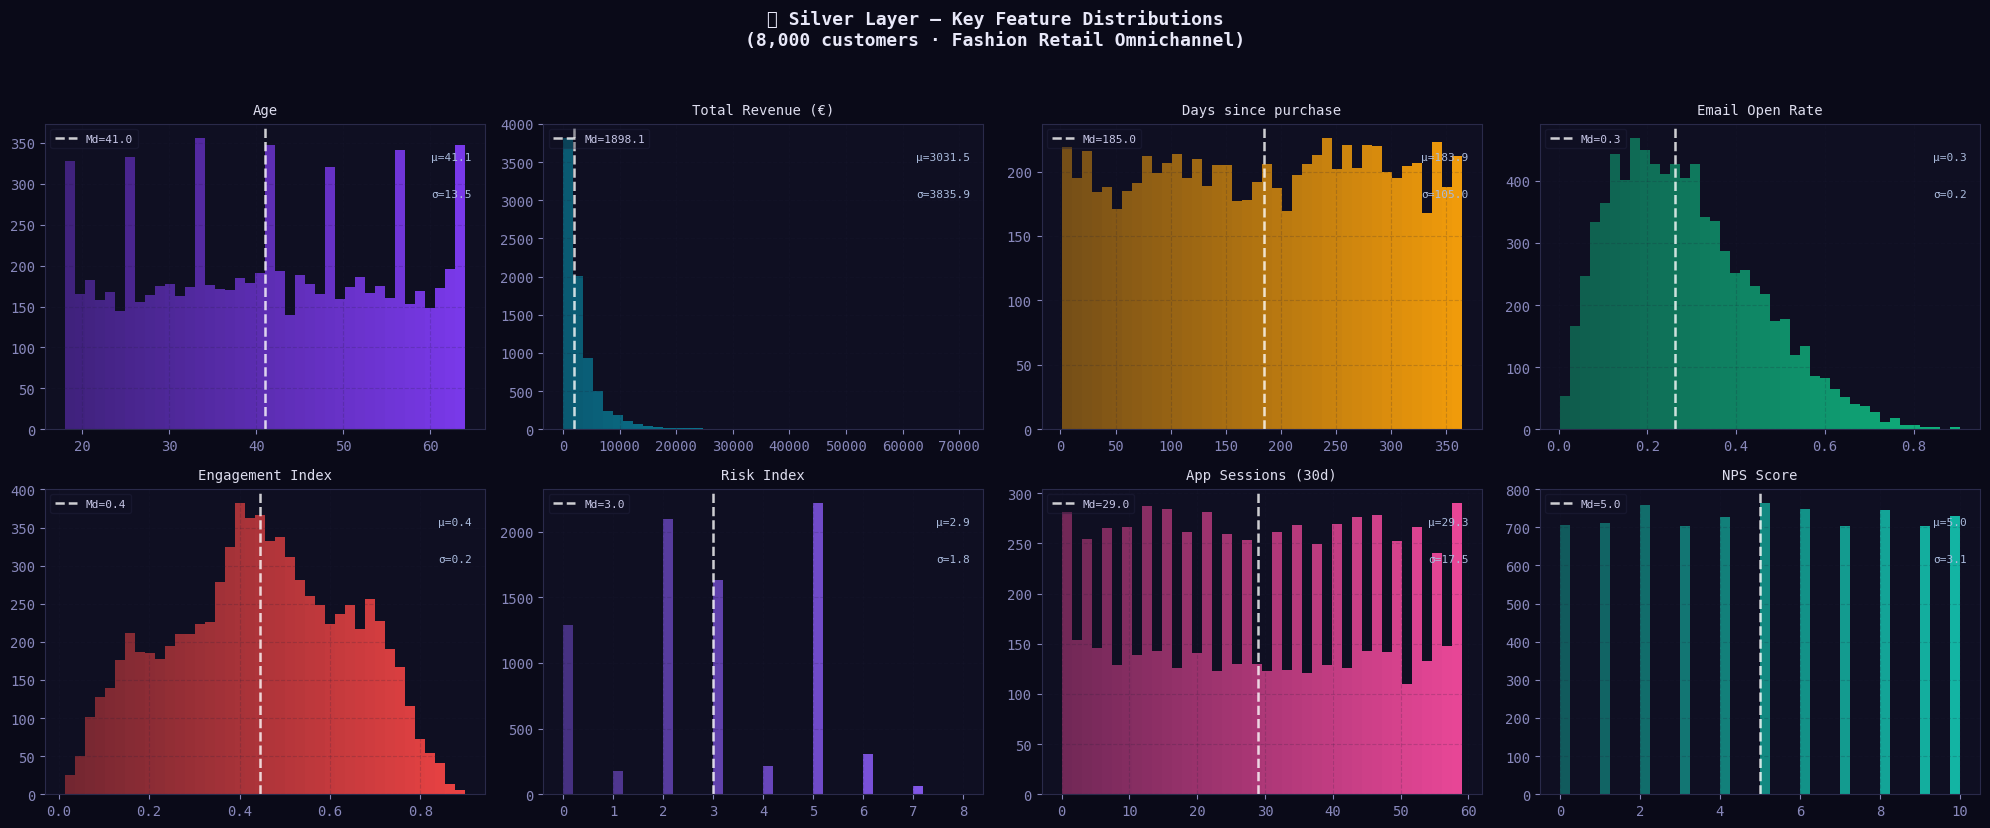


💡 Tip: skewed distributions (revenue/purchases) were handled with log1p transformation.


In [8]:
# ── Visualisation: Distribution of 8 Key Features
PLOT_FEATS = [
    ('age',                   'Age',                PAL[0]),
    ('total_revenue',         'Total Revenue (€)',   PAL[1]),
    ('last_purchase_days_ago','Days since purchase', PAL[2]),
    ('email_open_rate',       'Email Open Rate',     PAL[3]),
    ('engagement_index',      'Engagement Index',    PAL[4]),
    ('risk_index',            'Risk Index',          PAL[5]),
    ('app_sessions_30d',      'App Sessions (30d)',  PAL[6]),
    ('nps_score',             'NPS Score',           PAL[7]),
]

fig0, axes0 = plt.subplots(2, 4, figsize=(20, 8))
fig0.suptitle(
    '🥈 Silver Layer — Key Feature Distributions\n'
    f'({N_CUSTOMERS:,} customers · Fashion Retail Omnichannel)',
    fontsize=13, fontweight='bold', color='#e8e8f8', y=1.03
)

for ax, (col, label, color) in zip(axes0.flatten(), PLOT_FEATS):
    data = silver_df[col].dropna()
    n, bins, patches = ax.hist(data, bins=40, color=color, alpha=0.82, edgecolor='none')
    for i, p in enumerate(patches):
        p.set_alpha(0.45 + 0.55 * (i / len(patches)))
    med = data.median()
    ax.axvline(med, color='white', ls='--', lw=1.8, alpha=0.80, label=f'Md={med:.1f}')
    ax.set_title(label, fontsize=10, pad=7, color='#dde')
    ax.text(0.97, 0.88, f'μ={data.mean():.1f}', transform=ax.transAxes,
            ha='right', fontsize=8, color='#aabbdd')
    ax.text(0.97, 0.76, f'σ={data.std():.1f}', transform=ax.transAxes,
            ha='right', fontsize=8, color='#aabbdd')
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(True, alpha=0.18)

plt.tight_layout()
plt.savefig('reports/00_silver_features.png', dpi=135, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print("\n💡 Tip: skewed distributions (revenue/purchases) were handled with log1p transformation.")

---
## 🥇 Section 3 — Gold Layer: Analytical Tables for ML

> 🏷️ **For the business reader:** Gold Layer = report ready for the board.  
> Each Gold table answers exactly one business question.  
> No further cleaning, joining or calculating needed — just use it.

> ⚙️ **For the engineer:**  
> Two Gold tables with engineered targets:
> - **`churn_features.csv`** — features + binary target `churned` ∈ {0,1}
> - **`clv_features.csv`** — features + continuous target `clv_12m` ∈ [10, 5000]
>
> **CLV Target (Customer Lifetime Value):**
> $$CLV_{12m} = \text{clip}\left(\bar{v} \times n_{purchases} \times 0.15 + \mathcal{N}(0, 50),\; 10,\; 5000\right)$$
> - `0.15` = estimated gross margin (15%) — typical for fashion mid-market
> - `N(0, 50)` = realistic noise to vary CLV between similar customers
> - `clip(10, 5000)` = limits outliers and ensures positivity


In [9]:
# ── CLV target engineering
clv_target = np.clip(
    silver_df['avg_order_value'] * silver_df['total_purchases'] * 0.15 +
    np.random.normal(0, 50, len(silver_df)),
    10, 5000
)

# ── Gold tables
churn_gold = silver_df[FEATURE_COLS + ['customer_id','churned']].dropna()
clv_df     = silver_df[FEATURE_COLS + ['customer_id']].dropna().copy()
clv_df['clv_12m'] = clv_target[clv_df.index]

churn_gold.to_csv('data/gold/churn_features.csv', index=False)
clv_df.to_csv('data/gold/clv_features.csv', index=False)

print("✅ Gold Layer saved:")
print(f"   churn_features.csv → {len(churn_gold):,} rows · {len(FEATURE_COLS)} features")
print(f"     churn rate: {churn_gold['churned'].mean():.1%}  (positives: {churn_gold['churned'].sum():,})")
print(f"\n   clv_features.csv   → {len(clv_df):,} rows")
print(f"     Min: €{clv_df['clv_12m'].min():.2f}  ·  Median: €{clv_df['clv_12m'].median():.2f}")
print(f"     Mean: €{clv_df['clv_12m'].mean():.2f}  ·  Max: €{clv_df['clv_12m'].max():.2f}")
print(f"\n📊 CLV distribution by quartile:")
print(clv_df['clv_12m'].describe().round(2).to_string())

✅ Gold Layer saved:
   churn_features.csv → 8,000 rows · 25 features
     churn rate: 33.7%  (positives: 2,698)

   clv_features.csv   → 8,000 rows
     Min: €10.00  ·  Median: €288.24
     Mean: €453.75  ·  Max: €5000.00

📊 CLV distribution by quartile:
count    8000.00
mean      453.75
std       547.36
min        10.00
25%       125.92
50%       288.24
75%       571.93
max      5000.00


---
## 🔴 Section 4 — Churn Prediction (XGBoost Classifier)

> 🏷️ **For the business reader:** Churn = customer who stops buying.  
> The model gives a **score from 0% to 100%** for each customer: the probability of leaving.  
> The marketing team knows exactly who to call/email **before** the customer disappears.
>
> **Why XGBoost?**  
> Imagine 300 referees analysing whether a customer will leave. Each referee is a  
> "decision tree" looking at a few pieces of evidence. XGBoost combines all votes —  
> giving more weight to referees who made fewer mistakes. Result: a more accurate verdict.

> ⚙️ **For the engineer:**
> - `scale_pos_weight` = `n_neg / n_pos` — compensates class imbalance
> - **ROC-AUC** preferred over Accuracy on imbalanced data (threshold-free)
> - **Precision-Recall AUC** complements ROC when positives are a minority
>
> 📐 **XGBoost objective:**
> $$\mathcal{L} = \sum_i \ell(\hat{y}_i, y_i) + \sum_k \Omega(f_k)$$
> where $\Omega(f) = \gamma T + \frac{1}{2}\lambda \|\mathbf{w}\|^2$ (leaf + L2 regularisation)


In [10]:
# ── Prepare churn dataset
X   = churn_gold[FEATURE_COLS]
y   = churn_gold['churned'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
class_weight = (y == 0).sum() / (y == 1).sum()

print(f"📊 Churn Dataset:")
print(f"   Total: {len(X):,}  |  Train: {len(X_train):,}  |  Test: {len(X_test):,}")
print(f"   Churn rate: {y.mean():.1%}  |  scale_pos_weight: {class_weight:.2f}")
print()

# ── Train XGBoost Classifier
churn_model = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.04,
    subsample=0.80, colsample_bytree=0.80,
    scale_pos_weight=class_weight,
    eval_metric='auc', random_state=SEED,
)
churn_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

# ── Metrics
y_proba  = churn_model.predict_proba(X_test)[:, 1]
y_pred   = (y_proba > 0.50).astype(int)
auc      = roc_auc_score(y_test, y_proba)
ap_score = average_precision_score(y_test, y_proba)
report   = classification_report(y_test, y_pred, output_dict=True)
CHURN_AUC = auc; CHURN_AP = ap_score

print("─" * 56)
print("  CHURN MODEL — RESULTS")
print("─" * 56)
print(f"  ROC-AUC    : {auc:.4f}  {'✅ Good' if auc > 0.75 else '⚠️  Reasonable'}")
print(f"  PR-AUC (AP): {ap_score:.4f}")
print(f"  Precision  : {report['1']['precision']:.4f}")
print(f"  Recall     : {report['1']['recall']:.4f}")
print(f"  F1-Score   : {report['1']['f1-score']:.4f}")
print("─" * 56)
print(f"\n💡 ROC-AUC of {auc:.2f}: for any pair (customer who will leave,")
print(f"   customer who will stay), the model ranks correctly {auc:.0%} of the time.")

📊 Churn Dataset:
   Total: 8,000  |  Train: 6,400  |  Test: 1,600
   Churn rate: 33.7%  |  scale_pos_weight: 1.97

────────────────────────────────────────────────────────
  CHURN MODEL — RESULTS
────────────────────────────────────────────────────────
  ROC-AUC    : 0.7956  ✅ Good
  PR-AUC (AP): 0.6108
  Precision  : 0.5572
  Recall     : 0.8389
  F1-Score   : 0.6696
────────────────────────────────────────────────────────

💡 ROC-AUC of 0.80: for any pair (customer who will leave,
   customer who will stay), the model ranks correctly 80% of the time.


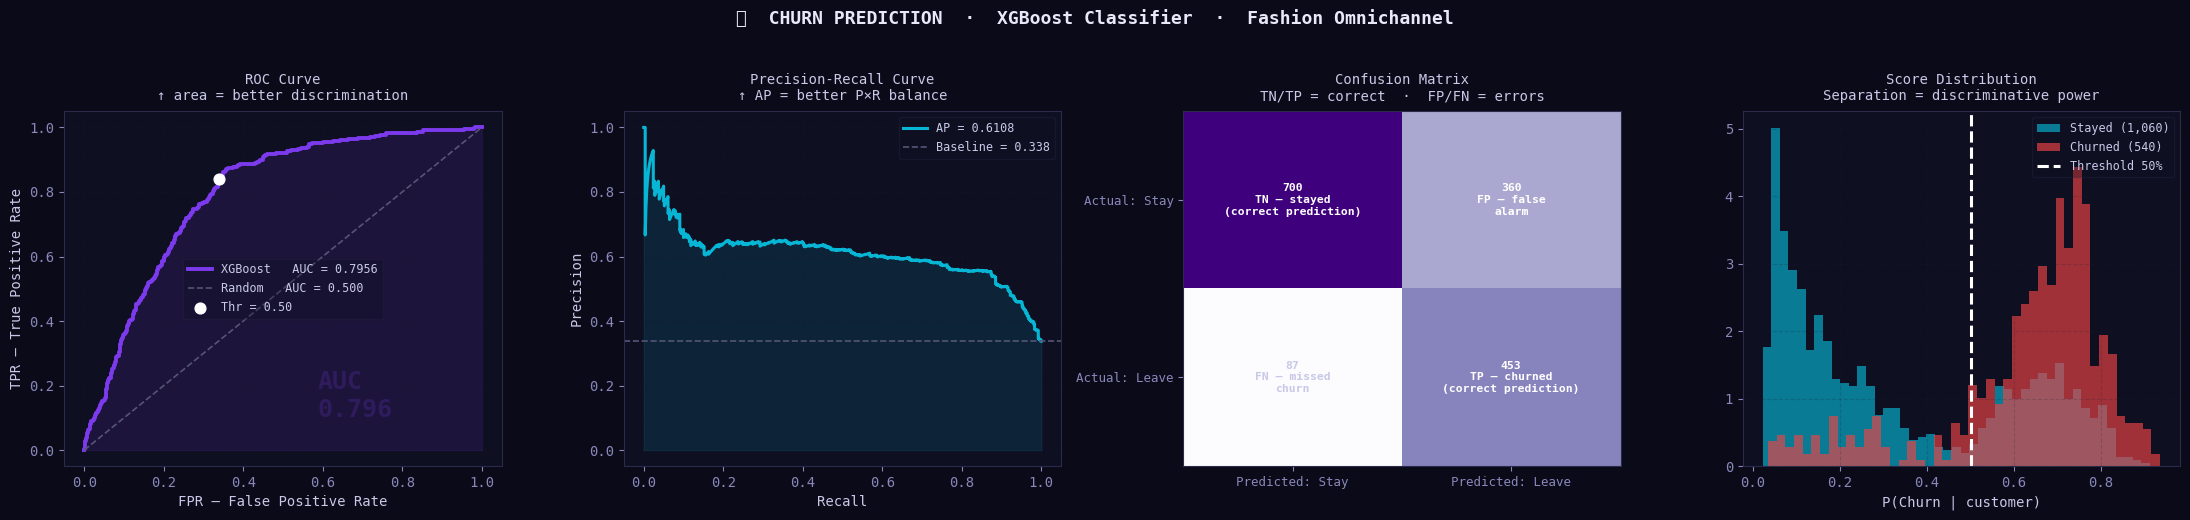

✅ Saved: reports/01_churn_perf.png


In [11]:
# ── Visualisation: Churn Model Performance (4 panels)
fpr, tpr, thrs = roc_curve(y_test, y_proba)
cm  = confusion_matrix(y_test, y_pred)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_proba)

fig1, axes1 = plt.subplots(1, 4, figsize=(22, 5))
fig1.suptitle(
    '🔴  CHURN PREDICTION  ·  XGBoost Classifier  ·  Fashion Omnichannel',
    fontsize=13, fontweight='bold', color='#e8e8f8', y=1.03
)

# 1. ROC Curve
axes1[0].fill_between(fpr, tpr, alpha=0.12, color=PAL[0])
axes1[0].plot(fpr, tpr, color=PAL[0], lw=2.8, label=f'XGBoost   AUC = {auc:.4f}')
axes1[0].plot([0,1],[0,1], '--', color='#555577', lw=1.2, label='Random   AUC = 0.500')
idx50 = np.argmin(np.abs(thrs - 0.50))
axes1[0].scatter([fpr[idx50]], [tpr[idx50]], color='white', s=60, zorder=5, label='Thr = 0.50')
axes1[0].set_title('ROC Curve\n↑ area = better discrimination', fontsize=10, pad=8)
axes1[0].set_xlabel('FPR — False Positive Rate')
axes1[0].set_ylabel('TPR — True Positive Rate')
axes1[0].legend(fontsize=8.5); axes1[0].grid(True, alpha=0.20)
axes1[0].text(0.58, 0.14, f'AUC\n{auc:.3f}', transform=axes1[0].transAxes,
              fontsize=18, color=PAL[0], fontweight='bold', alpha=0.20)

# 2. Precision-Recall Curve
axes1[1].fill_between(rec_curve, prec_curve, alpha=0.12, color=PAL[1])
axes1[1].plot(rec_curve, prec_curve, color=PAL[1], lw=2.2, label=f'AP = {ap_score:.4f}')
axes1[1].axhline(y_test.mean(), color='#555577', ls='--', lw=1.2,
                 label=f'Baseline = {y_test.mean():.3f}')
axes1[1].set_title('Precision-Recall Curve\n↑ AP = better P×R balance', fontsize=10, pad=8)
axes1[1].set_xlabel('Recall'); axes1[1].set_ylabel('Precision')
axes1[1].legend(fontsize=8.5); axes1[1].grid(True, alpha=0.20)

# 3. Confusion Matrix
annot = [
    [f'{cm[0,0]:,}\nTN — stayed\n(correct prediction)', f'{cm[0,1]:,}\nFP — false\nalarm'],
    [f'{cm[1,0]:,}\nFN — missed\nchurn',                f'{cm[1,1]:,}\nTP — churned\n(correct prediction)'],
]
axes1[2].imshow(cm, cmap='Purples', aspect='auto')
for i in range(2):
    for j in range(2):
        axes1[2].text(j, i, annot[i][j], ha='center', va='center', fontsize=8.2,
                      fontweight='bold',
                      color='white' if cm[i,j] > cm.max()*0.44 else '#c8c8e8')
axes1[2].set_xticks([0,1]); axes1[2].set_xticklabels(['Predicted: Stay','Predicted: Leave'], fontsize=9)
axes1[2].set_yticks([0,1]); axes1[2].set_yticklabels(['Actual: Stay','Actual: Leave'], fontsize=9)
axes1[2].set_title('Confusion Matrix\nTN/TP = correct  ·  FP/FN = errors', fontsize=10, pad=8)

# 4. Score Distribution
axes1[3].hist(y_proba[y_test==0], bins=45, alpha=0.65,
              color=PAL[1], label=f'Stayed ({(y_test==0).sum():,})', density=True)
axes1[3].hist(y_proba[y_test==1], bins=45, alpha=0.65,
              color=PAL[4], label=f'Churned ({(y_test==1).sum():,})', density=True)
axes1[3].axvline(0.50, color='white', ls='--', lw=2.2, label='Threshold 50%')
axes1[3].set_title('Score Distribution\nSeparation = discriminative power', fontsize=10, pad=8)
axes1[3].set_xlabel('P(Churn | customer)'); axes1[3].legend(fontsize=8.5); axes1[3].grid(True, alpha=0.20)

plt.tight_layout()
plt.savefig('reports/01_churn_perf.png', dpi=135, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print("✅ Saved: reports/01_churn_perf.png")

---
## 🔍 Section 5 — Explainable AI: Why does the model predict churn?

> 🏷️ **For the business reader:** Knowing a customer has an 85% chance of leaving is useful.  
> But knowing **why** is powerful.  
> It's the difference between a fire alarm (warns of fire) and the fire report  
> (tells you where the fire is and how to put it out).
>
> **SHAP** distributes the "blame" for a prediction across all variables.  
> If the model predicted 80%, SHAP says: *"50% came from '300 days without purchase',  
> 20% from 'NPS=2', 10% from 'zero app sessions'..."*

> ⚙️ **For the engineer:**
> - **TreeExplainer:** exact SHAP for tree ensembles — complexity $O(T \cdot L \cdot D)$
> - **SHAP value** $\phi_j(i)$: how much feature $j$ moved the prediction for sample $i$  
>   relative to the base value $\mathbb{E}[f(x)]$ (population average)
> - **Additive property:** $f(x) = \phi_0 + \sum_j \phi_j$ (exact sum = prediction)
> - **Beeswarm:** each point = 1 sample · x position = SHAP · colour = feature value
> - **Dependence plot:** detects feature interactions (colour = correlated feature)
> - **Waterfall:** individual additive decomposition (base → prediction = Σ SHAP)


In [12]:
# ── Compute SHAP values (TreeExplainer — exact for XGBoost)
print("🔍 Computing SHAP values with TreeExplainer...")
print("   Complexity: O(T × L × D) — may take 30-60s on Colab")

shap_explainer = shap.TreeExplainer(churn_model)
shap_values    = shap_explainer.shap_values(X_test.iloc[:600])

shap_imp_df = pd.DataFrame({
    'feature':  NICE,
    'mean_abs': np.abs(shap_values).mean(0),
}).sort_values('mean_abs', ascending=False)

print(f"\n✅ SHAP computed: {shap_values.shape[0]} samples × {shap_values.shape[1]} features")
print(f"\n📊 Top 10 Features by SHAP Importance:")
total_imp = shap_imp_df['mean_abs'].sum()
for i, (_, row) in enumerate(shap_imp_df.head(10).iterrows()):
    pct = row['mean_abs'] / total_imp * 100
    bar = '█' * int(row['mean_abs'] / shap_imp_df['mean_abs'].max() * 28)
    print(f"   {i+1:2}. {row['feature']:<28} {bar} {pct:.1f}%")
print(f"\n💡 Top driver: '{shap_imp_df.iloc[0]['feature']}'")
print(f"   Accounts for {shap_imp_df.iloc[0]['mean_abs']/total_imp:.0%} of total model importance")

🔍 Computing SHAP values with TreeExplainer...
   Complexity: O(T × L × D) — may take 30-60s on Colab

✅ SHAP computed: 600 samples × 25 features

📊 Top 10 Features by SHAP Importance:
    1. Days since purchase          ████████████████████████████ 28.8%
    2. Support tickets              ███████████ 12.0%
    3. Recency score                ██████████ 10.7%
    4. Risk index                   ██████████ 10.4%
    5. Email open rate              ████ 4.8%
    6. Returns rate                 ███ 3.9%
    7. Engagement                   ███ 3.2%
    8. Discount sensitivity         ██ 3.1%
    9. Age                          ██ 2.6%
   10. NPS (satisfaction)           ██ 2.3%

💡 Top driver: 'Days since purchase'
   Accounts for 29% of total model importance


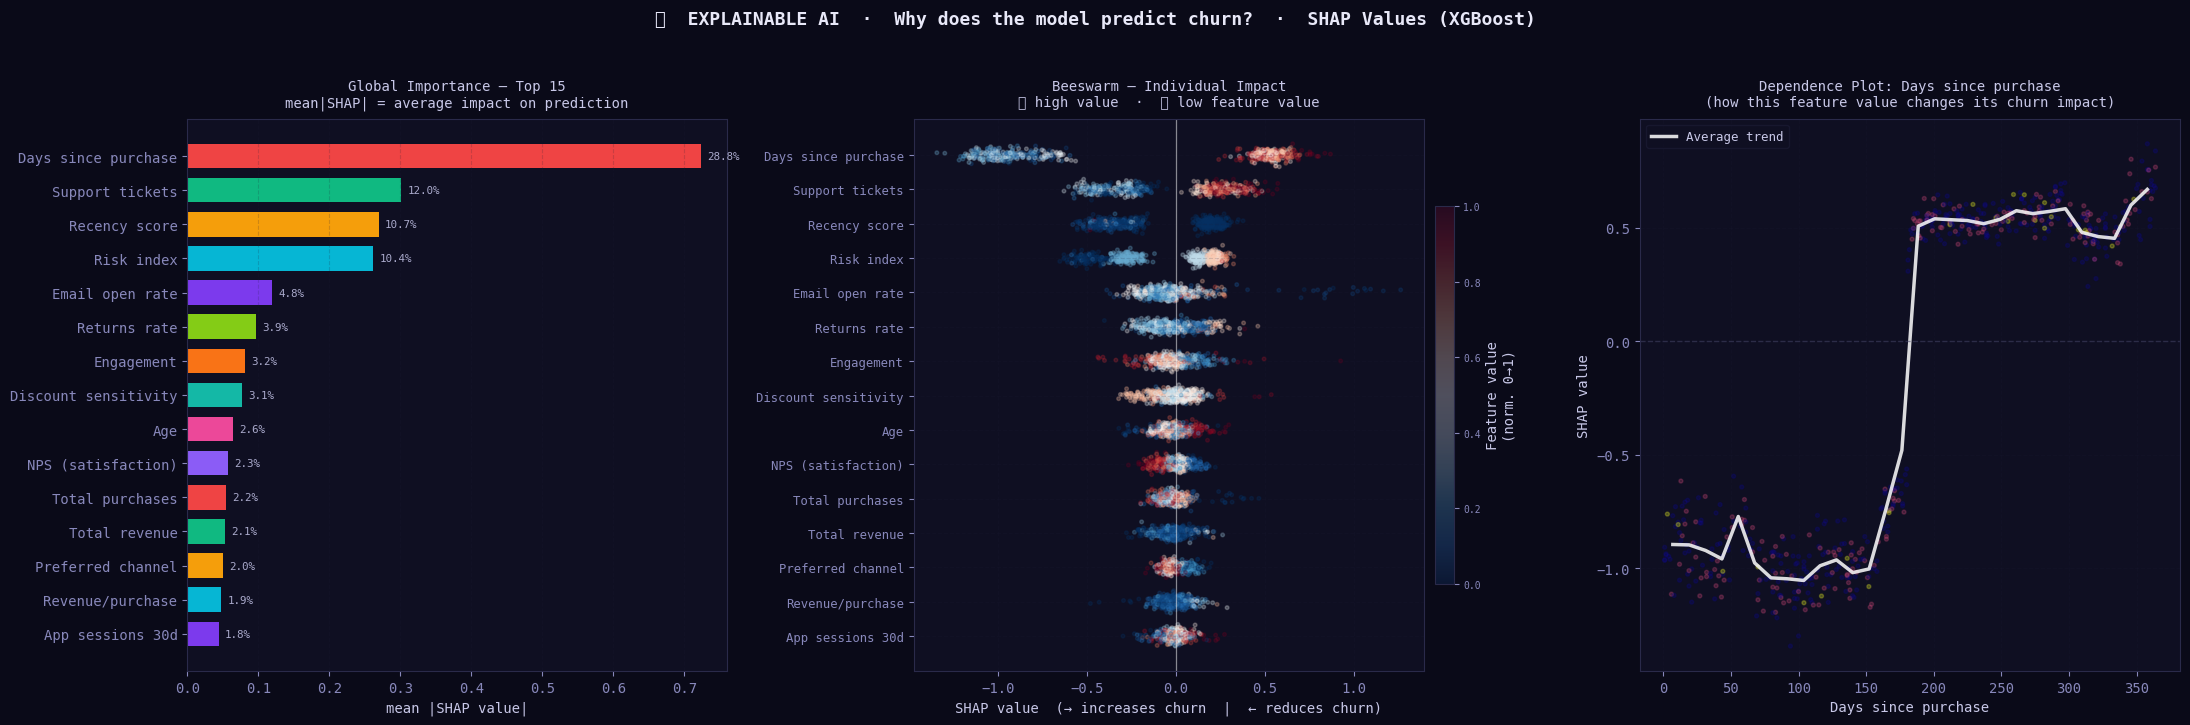

✅ Saved: reports/02_churn_shap_global.png


In [13]:
# ── SHAP Global: Bar + Beeswarm + Dependence Plot
sv_df  = pd.DataFrame(shap_values, columns=NICE)
raw_df = pd.DataFrame(X_test.iloc[:600].values, columns=NICE)
top15  = shap_imp_df.head(15)['feature'].tolist()

fig2, axes2 = plt.subplots(1, 3, figsize=(22, 7))
fig2.suptitle(
    '🔍  EXPLAINABLE AI  ·  Why does the model predict churn?  ·  SHAP Values (XGBoost)',
    fontsize=13, fontweight='bold', color='#e8e8f8', y=1.03
)

# 1. Bar: Global Importance
top15_df = shap_imp_df.head(15).iloc[::-1]
cols_bar = [PAL[i % len(PAL)] for i in range(15)]
bars2 = axes2[0].barh(top15_df['feature'], top15_df['mean_abs'],
                       color=cols_bar, edgecolor='none', height=0.72)
for bar, (_, row) in zip(bars2, top15_df.iterrows()):
    pct = row['mean_abs'] / total_imp * 100
    axes2[0].text(row['mean_abs'] + shap_imp_df['mean_abs'].max()*0.012,
                  bar.get_y()+bar.get_height()/2,
                  f'{pct:.1f}%', va='center', fontsize=7.8, color='#aaaacc')
axes2[0].set_title('Global Importance — Top 15\nmean|SHAP| = average impact on prediction',
                   fontsize=10, pad=9)
axes2[0].set_xlabel('mean |SHAP value|'); axes2[0].grid(True, alpha=0.18, axis='x')

# 2. Beeswarm
top15_rev = top15[::-1]
for idx, feat in enumerate(top15_rev):
    if feat not in sv_df.columns: continue
    vals  = sv_df[feat].values
    raw   = raw_df[feat].values
    rng   = raw.max() - raw.min() + 1e-9
    norm  = (raw - raw.min()) / rng
    jitter = np.random.normal(idx, 0.10, len(vals))
    sc2 = axes2[1].scatter(vals, jitter, c=norm, cmap='RdBu_r', alpha=0.28, s=7, vmin=0, vmax=1)
axes2[1].set_yticks(range(len(top15_rev))); axes2[1].set_yticklabels(top15_rev, fontsize=8.8)
axes2[1].axvline(0, color='white', lw=0.9, alpha=0.5)
axes2[1].set_title('Beeswarm — Individual Impact\n🔴 high value  ·  🔵 low feature value',
                   fontsize=10, pad=9)
axes2[1].set_xlabel('SHAP value  (→ increases churn  |  ← reduces churn)')
axes2[1].grid(True, alpha=0.15)
cbar2 = plt.colorbar(sc2, ax=axes2[1], label='Feature value\n(norm. 0→1)', pad=0.02, fraction=0.035)
cbar2.ax.tick_params(labelsize=7)

# 3. Dependence Plot (top feature)
top1 = shap_imp_df.iloc[0]['feature']
raw1 = raw_df[top1].values; sv1 = sv_df[top1].values
bmean, bedge, _ = binned_statistic(raw1, sv1, statistic='mean', bins=30)
bcenter = (bedge[:-1]+bedge[1:])/2
axes2[2].scatter(raw1, sv1, c=raw_df.iloc[:, 1].values, cmap='plasma', alpha=0.28, s=8)
axes2[2].plot(bcenter, bmean, color='white', lw=2.5, alpha=0.85, label='Average trend')
axes2[2].axhline(0, color='#444466', ls='--', lw=1, alpha=0.55)
axes2[2].set_title(f'Dependence Plot: {top1}\n(how this feature value changes its churn impact)',
                   fontsize=10, pad=9)
axes2[2].set_xlabel(top1); axes2[2].set_ylabel('SHAP value')
axes2[2].legend(fontsize=9); axes2[2].grid(True, alpha=0.18)

plt.tight_layout()
plt.savefig('reports/02_churn_shap_global.png', dpi=135, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print("✅ Saved: reports/02_churn_shap_global.png")

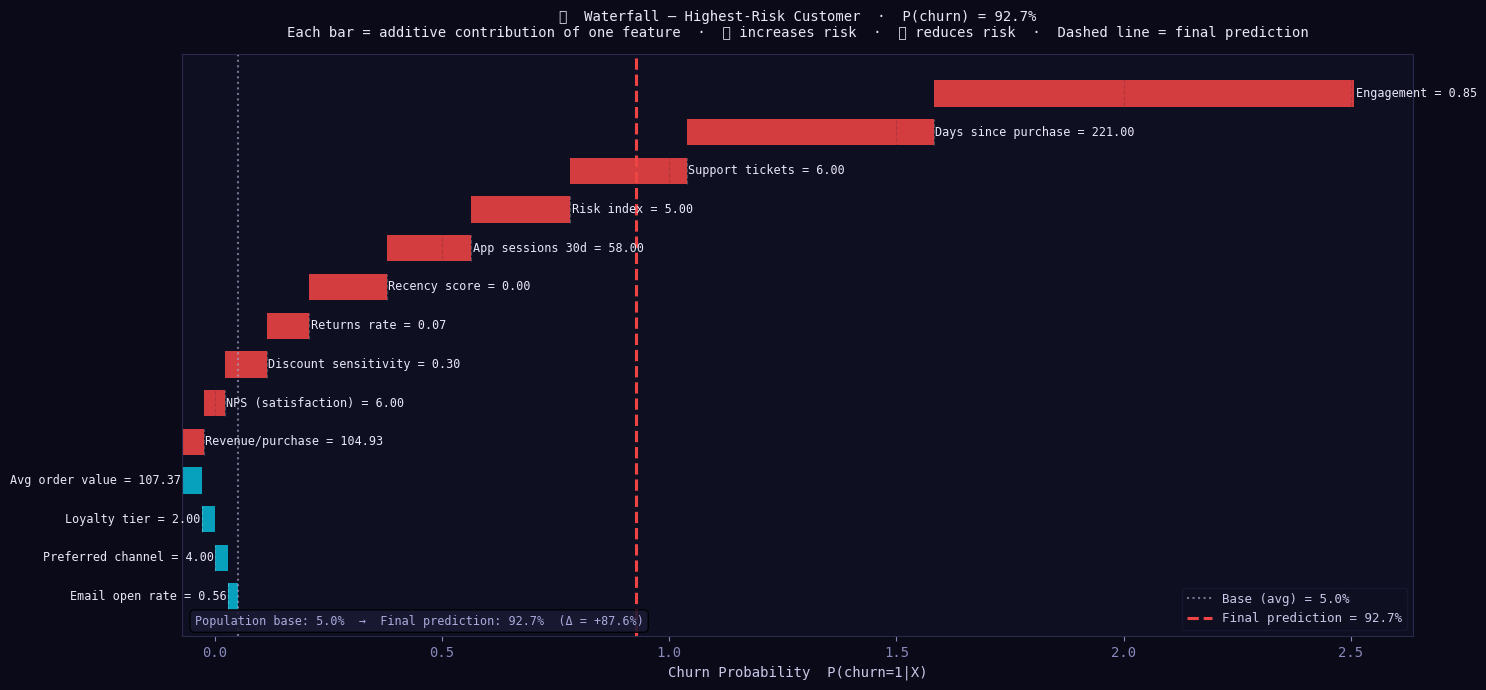


💡 CRM USAGE:
   → Customer #336 has 93% churn risk
   → Top driver: 'Engagement' (SHAP=+0.9259)
   → Recommended action: personalised retention campaign
   → Priority: 🚨 URGENT


In [15]:
# ── Waterfall Plot: Individual Explanation (highest-risk customer)

# SHAP was computed on the first 600 samples of X_test
X_test_shap = X_test.iloc[:600]
y_proba_shap = churn_model.predict_proba(X_test_shap)[:, 1]

# Find highest-risk customer WITHIN the 600 SHAP samples
hi_idx   = int(np.argmax(y_proba_shap))
hi_prob  = y_proba_shap[hi_idx]
sv_hi    = shap_values[hi_idx]
raw_hi   = X_test_shap.iloc[hi_idx].values
base_val = float(shap_explainer.expected_value)

order_hi   = np.argsort(np.abs(sv_hi))[-14:]
feats_hi   = [NICE[i] for i in order_hi]
vals_hi    = [sv_hi[i]  for i in order_hi]
raws_hi    = [raw_hi[i] for i in order_hi]
cumulative = [base_val + sum(vals_hi[:i]) for i in range(len(vals_hi)+1)]

fig8, ax8 = plt.subplots(figsize=(15, 7))
for i, (feat, val, rv, cum_start) in enumerate(zip(feats_hi, vals_hi, raws_hi, cumulative[:-1])):
    color = PAL[4] if val > 0 else PAL[1]
    ax8.barh(i, val, left=cum_start, color=color, alpha=0.88, edgecolor='none', height=0.68)
    ax8.text(cum_start+val+(0.003 if val>=0 else -0.003), i,
             f'{feat} = {rv:.2f}', va='center', ha='left' if val>=0 else 'right',
             fontsize=8.5, color='#e8e8f8')
    if i < len(vals_hi)-1:
        ax8.plot([cumulative[i+1],cumulative[i+1]], [i-0.34, i+0.34],
                 '--', color='white', alpha=0.25, lw=0.8)

ax8.axvline(base_val, color='#aaaacc', ls=':', lw=1.5, alpha=0.65,
            label=f'Base (avg) = {base_val:.1%}')
ax8.axvline(hi_prob, color=PAL[4], ls='--', lw=2.2,
            label=f'Final prediction = {hi_prob:.1%}')
ax8.set_yticks([]); ax8.set_xlabel('Churn Probability  P(churn=1|X)')
ax8.set_title(
    f'🔍  Waterfall — Highest-Risk Customer  ·  P(churn) = {hi_prob:.1%}\n'
    'Each bar = additive contribution of one feature  '
    '·  🔴 increases risk  ·  🔵 reduces risk  ·  Dashed line = final prediction',
    fontsize=10, pad=12, color='#e8e8f8'
)
ax8.legend(fontsize=9, loc='lower right'); ax8.grid(True, alpha=0.18, axis='x')
ax8.text(0.01, 0.02,
         f'Population base: {base_val:.1%}  →  Final prediction: {hi_prob:.1%}  (Δ = +{hi_prob-base_val:.1%})',
         transform=ax8.transAxes, fontsize=8.5, color='#aaaadd',
         bbox=dict(boxstyle='round,pad=0.4', facecolor='#1a1a32', alpha=0.88))
plt.tight_layout()
plt.savefig('reports/08_shap_waterfall.png', dpi=135, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print(f"\n💡 CRM USAGE:")
print(f"   → Customer #{X_test_shap.index[hi_idx]} has {hi_prob:.0%} churn risk")
print(f"   → Top driver: '{feats_hi[-1]}' (SHAP={vals_hi[-1]:+.4f})")
print(f"   → Recommended action: personalised retention campaign")
print(f"   → Priority: {'🚨 URGENT' if hi_prob > 0.7 else '🔴 HIGH' if hi_prob > 0.5 else '🟡 MEDIUM'}")

---
## 💰 Section 6 — CLV Prediction (Customer Lifetime Value)

> 🏷️ **For the business reader:** CLV = how much each customer will spend in the next 12 months.  
> With this, the business can decide **how much it's worth investing** to retain each customer.  
> Spending €200 to save a €50 customer makes no sense.  
> But spending €200 to save a €2,000 customer is profit.

> ⚙️ **For the engineer:**
> - **Regression** problem (continuous output, not probability)
> - XGBoost Regressor with the same architecture — hyperparameters can be tuned independently
> - **MAE (Mean Absolute Error):** average error in € — business metric, interpretable by the CMO
> - **R²:** % of CLV variance explained — goodness of fit
> - **Residual plot:** verifies absence of pattern (homoscedasticity of errors)
>
> 📐 **Simplified CLV formula:**
> $$CLV = \sum_{t=1}^{T} \frac{Revenue_t \times margin}{(1+r)^t} \approx \bar{v} \times n \times 0.15$$


In [16]:
# ── Train CLV Regressor
Xc = clv_df[FEATURE_COLS]
yc = clv_df['clv_12m']

Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.20, random_state=SEED)

clv_model = XGBRegressor(
    n_estimators=300, max_depth=5, learning_rate=0.04,
    subsample=0.80, colsample_bytree=0.80, random_state=SEED,
)
clv_model.fit(Xc_train, yc_train)

yc_pred = clv_model.predict(Xc_test)
all_clv = clv_model.predict(Xc)
mae  = mean_absolute_error(yc_test, yc_pred)
rmse = np.sqrt(mean_squared_error(yc_test, yc_pred))
r2   = r2_score(yc_test, yc_pred)
CLV_R2 = r2; CLV_MAE = mae

print("─" * 56)
print("  CLV MODEL — RESULTS")
print("─" * 56)
print(f"  MAE    : €{mae:.2f}  ← average error per customer")
print(f"  RMSE   : €{rmse:.2f}  ← penalises large errors")
print(f"  R²     : {r2:.4f}  {'✅ Excellent' if r2>0.90 else '✅ Good' if r2>0.70 else '⚠️'}")
print("─" * 56)
print(f"\n  Total CLV forecast (base): €{all_clv.sum():,.0f}")
print(f"  Average CLV per customer : €{all_clv.mean():,.2f}")
print(f"\n💡 The model is off by an average of €{mae:.0f} per customer.")

────────────────────────────────────────────────────────
  CLV MODEL — RESULTS
────────────────────────────────────────────────────────
  MAE    : €40.27  ← average error per customer
  RMSE   : €52.54  ← penalises large errors
  R²     : 0.9898  ✅ Excellent
────────────────────────────────────────────────────────

  Total CLV forecast (base): €3,627,030
  Average CLV per customer : €453.38

💡 The model is off by an average of €40 per customer.


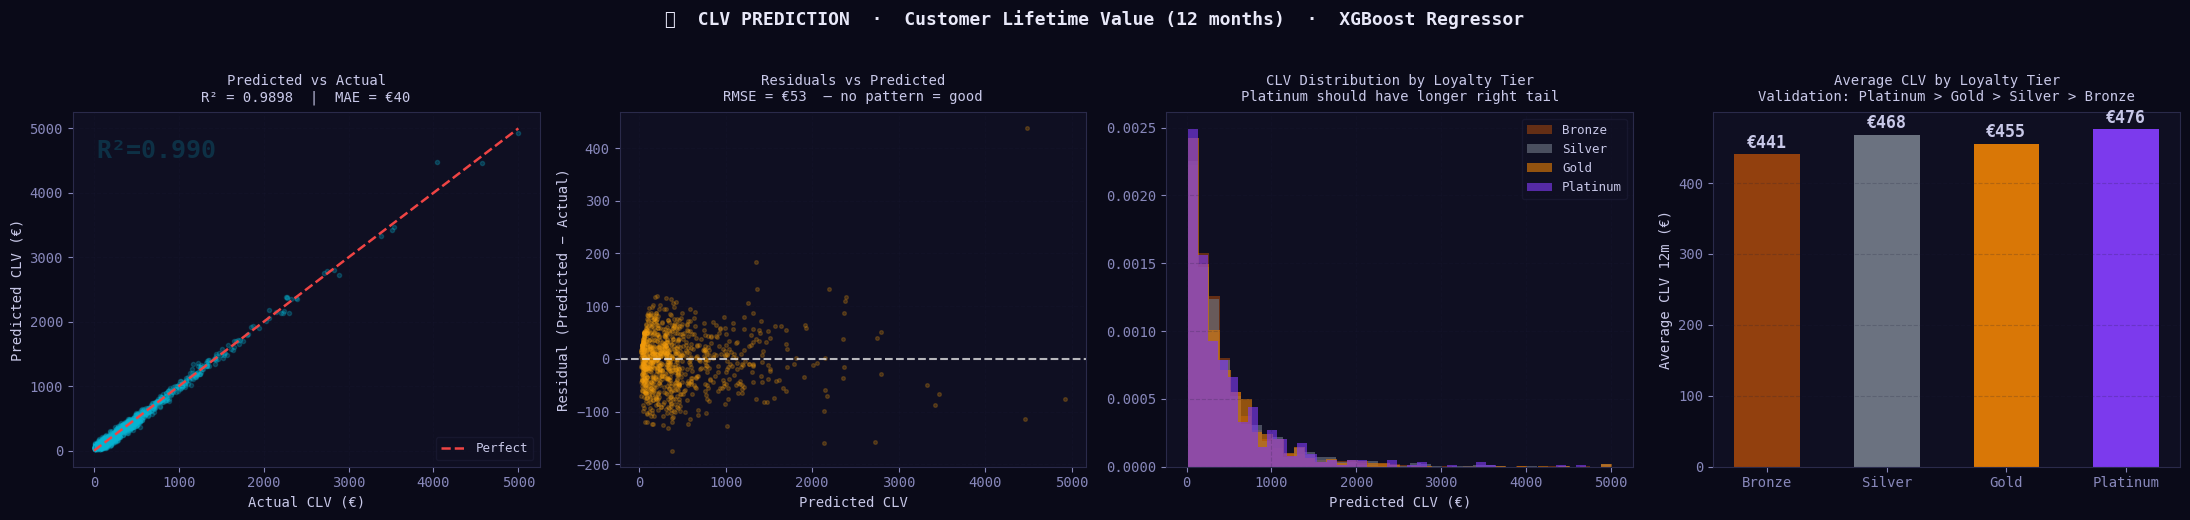

✅ Saved: reports/03_clv_perf.png


In [17]:
# ── Visualisation: CLV Performance (4 panels)
residuals = yc_pred - yc_test.values
clv_with_tier = pd.DataFrame({
    'clv':  all_clv,
    'tier': silver_df.loc[Xc.index, 'loyalty_tier'].values
})
tier_order  = ['Bronze','Silver','Gold','Platinum']
tier_colors = ['#92400e','#6b7280','#d97706','#7c3aed']

fig3, axes3 = plt.subplots(1, 4, figsize=(22, 5))
fig3.suptitle(
    '💰  CLV PREDICTION  ·  Customer Lifetime Value (12 months)  ·  XGBoost Regressor',
    fontsize=13, fontweight='bold', color='#e8e8f8', y=1.03
)

# 1. Predicted vs Actual
samp_idx = np.random.choice(len(yc_test), min(1000, len(yc_test)), replace=False)
axes3[0].scatter(yc_test.iloc[samp_idx], yc_pred[samp_idx], alpha=0.25, color=PAL[1], s=9)
mv = max(float(yc_test.max()), float(yc_pred.max()))
axes3[0].plot([0,mv],[0,mv], '--', color=PAL[4], lw=1.8, label='Perfect')
axes3[0].set_title(f'Predicted vs Actual\nR² = {r2:.4f}  |  MAE = €{mae:.0f}', fontsize=10, pad=8)
axes3[0].set_xlabel('Actual CLV (€)'); axes3[0].set_ylabel('Predicted CLV (€)')
axes3[0].legend(fontsize=9); axes3[0].grid(True, alpha=0.20)
axes3[0].text(0.05, 0.87, f'R²={r2:.3f}', transform=axes3[0].transAxes,
              fontsize=18, color=PAL[1], fontweight='bold', alpha=0.20)

# 2. Residual Plot
axes3[1].scatter(yc_pred[samp_idx], residuals[samp_idx], alpha=0.22, color=PAL[2], s=7)
axes3[1].axhline(0, color='white', ls='--', lw=1.5, alpha=0.70)
axes3[1].set_title(f'Residuals vs Predicted\nRMSE = €{rmse:.0f}  — no pattern = good', fontsize=10, pad=8)
axes3[1].set_xlabel('Predicted CLV'); axes3[1].set_ylabel('Residual (Predicted − Actual)')
axes3[1].grid(True, alpha=0.20)

# 3. Distribution by Loyalty Tier
for i, tier in enumerate(tier_order):
    sub = clv_with_tier[clv_with_tier['tier']==tier]['clv']
    if len(sub) > 0:
        axes3[2].hist(sub, bins=40, alpha=0.65, label=tier, color=tier_colors[i], density=True)
axes3[2].set_title('CLV Distribution by Loyalty Tier\nPlatinum should have longer right tail',
                   fontsize=10, pad=8)
axes3[2].set_xlabel('Predicted CLV (€)'); axes3[2].legend(fontsize=9); axes3[2].grid(True, alpha=0.20)

# 4. Average CLV by Tier
tier_means = {t: clv_with_tier[clv_with_tier['tier']==t]['clv'].mean()
              for t in tier_order if (clv_with_tier['tier']==t).any()}
b3 = axes3[3].bar(list(tier_means.keys()), list(tier_means.values()),
                   color=tier_colors[:len(tier_means)], width=0.55, edgecolor='none')
for bar, v in zip(b3, tier_means.values()):
    axes3[3].text(bar.get_x()+bar.get_width()/2, v+9, f'€{v:.0f}',
                  ha='center', fontsize=12, fontweight='bold')
axes3[3].set_title('Average CLV by Loyalty Tier\nValidation: Platinum > Gold > Silver > Bronze',
                   fontsize=10, pad=8)
axes3[3].set_ylabel('Average CLV 12m (€)'); axes3[3].grid(True, alpha=0.20, axis='y')

plt.tight_layout()
plt.savefig('reports/03_clv_perf.png', dpi=135, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print("✅ Saved: reports/03_clv_perf.png")

---
## 🔍 Section 7 — XAI for CLV: What drives a customer's future value?

> 🏷️ **For the business reader:** The CLV model knows a customer will spend €800,  
> but doesn't tell us why automatically. SHAP explains:  
> *"€300 came from 60 app sessions; €200 because they're Platinum;  
> €150 because they've been buying for 5 years..."*  
> This allows creating products and campaigns focused on the right factors.

> ⚙️ **For the engineer:**
> - SHAP for regression: values in **monetary unit €** (not probability)
> - `mean|SHAP|` = average absolute impact on CLV prediction in euros
> - Dependence plot for the top-1 feature reveals the underlying functional relationship
> - Compare top features of Churn vs CLV — identify strategic conflicts


🔍 Computing SHAP for CLV (regression)...
✅ CLV SHAP: 500 samples · values in €

📊 Top 10 Features by SHAP Importance (CLV):
    1. Total revenue                €256.23
    2. Monetary score               €56.38
    3. Revenue/purchase             €19.66
    4. Total purchases              €15.50
    5. Avg order value              €2.77
    6. Email open rate              €1.86
    7. Returns rate                 €1.61
    8. Days since purchase          €1.07
    9. Age                          €0.96
   10. Engagement                   €0.93


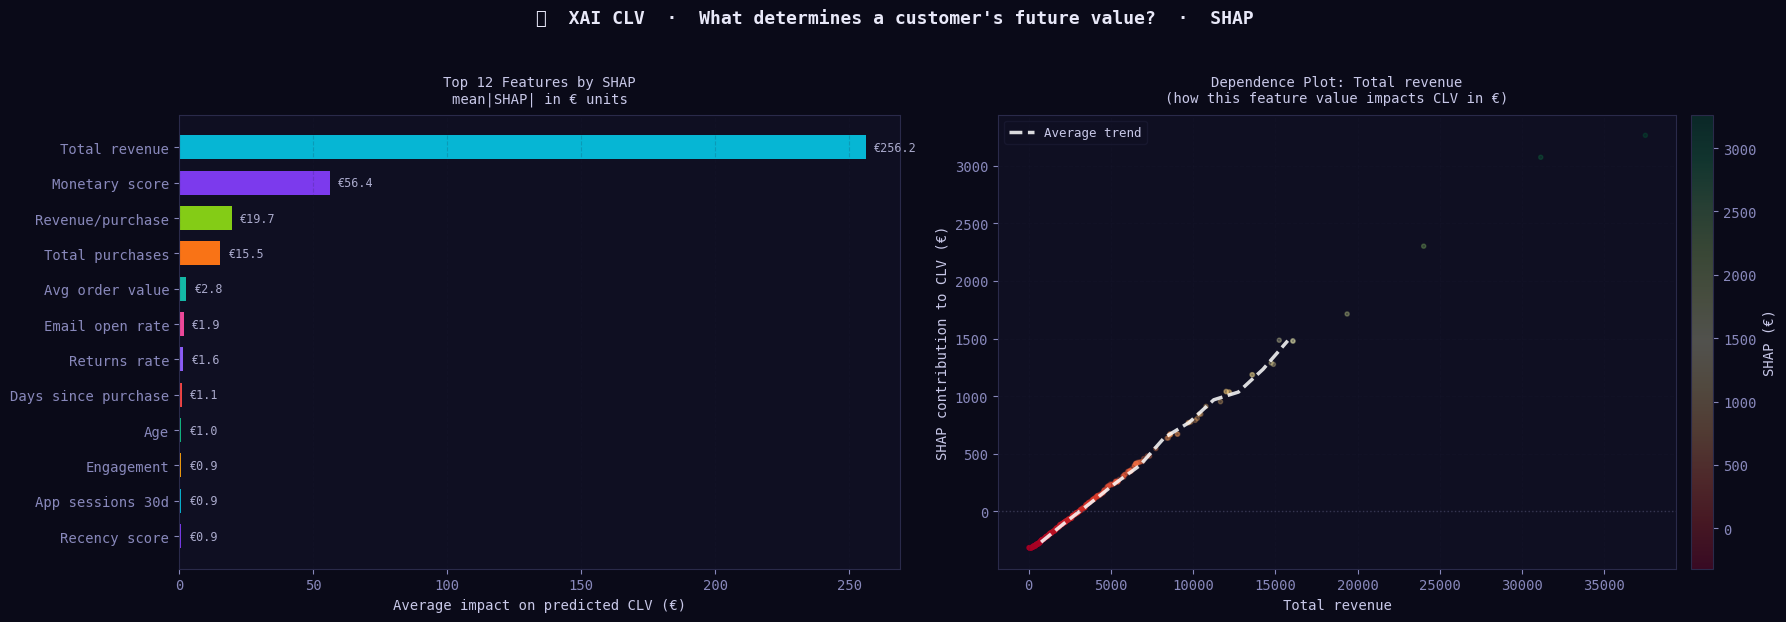

✅ Saved: reports/04_clv_shap.png


In [18]:
# ── CLV SHAP
print("🔍 Computing SHAP for CLV (regression)...")
clv_explainer = shap.TreeExplainer(clv_model)
clv_sv        = clv_explainer.shap_values(Xc_test.iloc[:500])

clv_shap_df = pd.DataFrame({
    'feature': NICE,
    'shap':    np.abs(clv_sv).mean(0),
}).sort_values('shap', ascending=False)

print(f"✅ CLV SHAP: {clv_sv.shape[0]} samples · values in €")
print(f"\n📊 Top 10 Features by SHAP Importance (CLV):")
for i, (_, row) in enumerate(clv_shap_df.head(10).iterrows()):
    print(f"   {i+1:2}. {row['feature']:<28} €{row['shap']:.2f}")

fig4, axes4 = plt.subplots(1, 2, figsize=(18, 6))
fig4.suptitle(
    '🔍  XAI CLV  ·  What determines a customer\'s future value?  ·  SHAP',
    fontsize=13, fontweight='bold', color='#e8e8f8', y=1.03
)

# Bar
top12_clv = clv_shap_df.head(12).iloc[::-1]
cols4 = [PAL[i % len(PAL)] for i in range(12)]
axes4[0].barh(top12_clv['feature'], top12_clv['shap'], color=cols4, edgecolor='none', height=0.68)
for _, (feat, val) in top12_clv.iterrows():
    axes4[0].text(val+clv_shap_df['shap'].max()*0.012,
                  list(top12_clv['feature']).index(feat),
                  f'€{val:.1f}', va='center', fontsize=8.5, color='#aaaacc')
axes4[0].set_title('Top 12 Features by SHAP\nmean|SHAP| in € units', fontsize=10, pad=9)
axes4[0].set_xlabel('Average impact on predicted CLV (€)'); axes4[0].grid(True, alpha=0.18, axis='x')

# Dependence Plot
top1_name = clv_shap_df.iloc[0]['feature']
raw_top1  = pd.DataFrame(Xc_test.iloc[:500].values, columns=NICE)[top1_name].values
sv_top1   = clv_sv[:, clv_shap_df.index[0]]
bmean, bedge, _ = binned_statistic(raw_top1, sv_top1, statistic='mean', bins=25)
bcenter = (bedge[:-1]+bedge[1:])/2
sc4 = axes4[1].scatter(raw_top1, sv_top1, c=sv_top1, cmap='RdYlGn', alpha=0.28, s=9)
axes4[1].plot(bcenter, bmean, '--', color='white', lw=2.5, alpha=0.85, label='Average trend')
axes4[1].axhline(0, color='#555577', ls=':', lw=1, alpha=0.55)
axes4[1].set_title(f'Dependence Plot: {top1_name}\n(how this feature value impacts CLV in €)',
                   fontsize=10, pad=9)
axes4[1].set_xlabel(top1_name); axes4[1].set_ylabel('SHAP contribution to CLV (€)')
axes4[1].legend(fontsize=9); axes4[1].grid(True, alpha=0.18)
plt.colorbar(sc4, ax=axes4[1], label='SHAP (€)', pad=0.02, fraction=0.04)

plt.tight_layout()
plt.savefig('reports/04_clv_shap.png', dpi=135, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print("✅ Saved: reports/04_clv_shap.png")

---
## 👥 Section 8 — Customer Segmentation (KMeans)

> 🏷️ **For the business reader:** Segmentation = grouping similar customers.  
> Like dividing a school class into groups:  
> those who study every day, those who study only the night before, those who never study.  
> Each group needs a different approach — just as each segment  
> needs a different campaign.

> ⚙️ **For the engineer:**
> - **KMeans** minimises inertia: $\sum_k \sum_{x \in C_k} \|x - \mu_k\|^2$
> - **Optimal K via Silhouette Score:** $s(i) = \frac{b(i) - a(i)}{\max(a(i),b(i))}$  
>   where $a(i)$ = average intra-cluster distance, $b(i)$ = distance to nearest cluster
> - `StandardScaler` mandatory — KMeans uses Euclidean distance (scale-sensitive)
> - `n_init=15` — multiple initialisations to avoid local minima


In [19]:
# ── Prepare segmentation data
seg_data   = silver_df[SEG_COLS].fillna(0)
seg_scaler = StandardScaler()
seg_scaled = seg_scaler.fit_transform(seg_data)

print(f"✅ Normalised data: {seg_scaled.shape[0]:,} × {seg_scaled.shape[1]}")
print()

# ── Find optimal K via Silhouette
k_range, silhouettes, inertias = range(2, 11), [], []
print("🔍 Testing K from 2 to 10 (Silhouette Score):")

for k in k_range:
    km  = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    lbl = km.fit_predict(seg_scaled)
    sil = silhouette_score(seg_scaled, lbl, sample_size=2500)
    silhouettes.append(sil)
    inertias.append(km.inertia_)
    bar    = '█' * int(sil * 55)
    best   = '← OPTIMAL' if k == (2+int(np.argmax(silhouettes))) else ''
    print(f"   K={k:2}  Sil={sil:.4f}  {bar} {best}")

best_k   = 2 + int(np.argmax(silhouettes))
best_sil = max(silhouettes)
SEG_SIL  = best_sil
print(f"\n✅ Optimal K = {best_k}  (Silhouette = {best_sil:.4f})")

✅ Normalised data: 8,000 × 9

🔍 Testing K from 2 to 10 (Silhouette Score):
   K= 2  Sil=0.2210  ████████████ ← OPTIMAL
   K= 3  Sil=0.1352  ███████ 
   K= 4  Sil=0.1244  ██████ 
   K= 5  Sil=0.1014  █████ 
   K= 6  Sil=0.1087  █████ 
   K= 7  Sil=0.1192  ██████ 
   K= 8  Sil=0.1179  ██████ 
   K= 9  Sil=0.1126  ██████ 
   K=10  Sil=0.1112  ██████ 

✅ Optimal K = 2  (Silhouette = 0.2210)


In [20]:
# ── Train final segmentation model
seg_model = KMeans(n_clusters=best_k, random_state=SEED, n_init=15)
silver_df['segment'] = seg_model.fit_predict(seg_scaled)

# ── Automatic naming by cluster profile
seg_profiles = silver_df.groupby('segment').agg(
    n_customers    = ('customer_id',            'count'),
    avg_revenue    = ('total_revenue',          'mean'),
    days_inactive  = ('last_purchase_days_ago', 'mean'),
    avg_purchases  = ('total_purchases',        'mean'),
    avg_engagement = ('engagement_index',       'mean'),
    churn_rate     = ('churned',                'mean'),
).round(2)

SEGMENT_NAMES = {}
q75_rev = seg_profiles['avg_revenue'].quantile(0.75)
q75_ina = seg_profiles['days_inactive'].quantile(0.75)
q75_pur = seg_profiles['avg_purchases'].quantile(0.75)
q25_eng = seg_profiles['avg_engagement'].quantile(0.25)

for seg, row in seg_profiles.iterrows():
    if row['avg_revenue'] >= q75_rev and row['days_inactive'] < 60:
        SEGMENT_NAMES[seg] = 'VIP Champions'
    elif row['days_inactive'] >= q75_ina:
        SEGMENT_NAMES[seg] = 'At Risk / Inactive'
    elif row['avg_purchases'] >= q75_pur:
        SEGMENT_NAMES[seg] = 'High Potential'
    elif row['avg_engagement'] <= q25_eng:
        SEGMENT_NAMES[seg] = 'Low Engagement'
    else:
        SEGMENT_NAMES[seg] = f'Core Segment {seg}'

silver_df['seg_name'] = silver_df['segment'].map(SEGMENT_NAMES)

print("📊 SEGMENT PROFILES:")
print("─" * 80)
sp = seg_profiles.copy()
sp.insert(0, 'Name', sp.index.map(SEGMENT_NAMES))
print(sp[['Name','n_customers','avg_revenue','days_inactive',
          'avg_purchases','avg_engagement','churn_rate']].to_string())
print("─" * 80)

📊 SEGMENT PROFILES:
────────────────────────────────────────────────────────────────────────────────
                       Name  n_customers  avg_revenue  days_inactive  avg_purchases  avg_engagement  churn_rate
segment                                                                                                        
0        At Risk / Inactive          991     10502.25         184.22          55.59            0.46        0.34
1            Low Engagement         7009      1975.16         183.82          37.58            0.44        0.34
────────────────────────────────────────────────────────────────────────────────


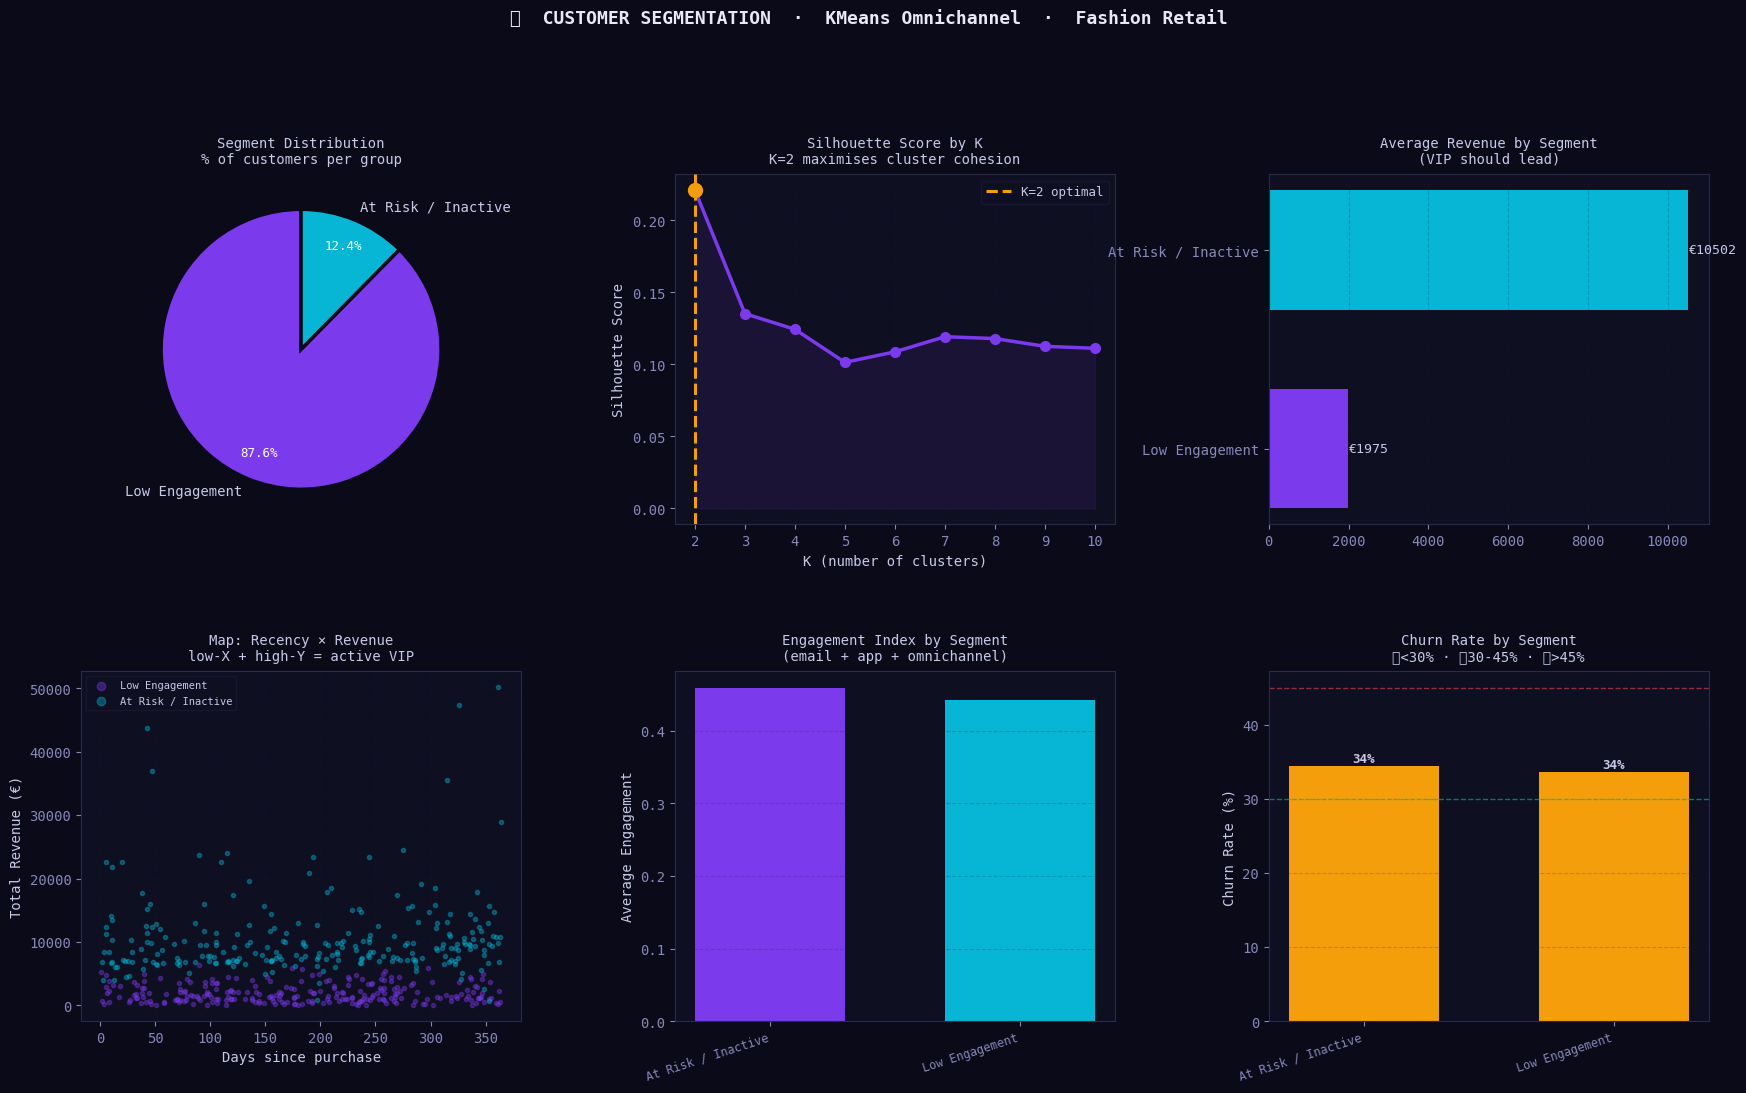

✅ Saved: reports/05_segmentation.png


In [21]:
# ── Visualisation: Segmentation (2×3 grid)
fig5 = plt.figure(figsize=(21, 11))
fig5.suptitle(
    '👥  CUSTOMER SEGMENTATION  ·  KMeans Omnichannel  ·  Fashion Retail',
    fontsize=13, fontweight='bold', color='#e8e8f8', y=1.03
)
gs5 = gridspec.GridSpec(2, 3, figure=fig5, hspace=0.42, wspace=0.35)
axes5 = [fig5.add_subplot(gs5[r, c]) for r in range(2) for c in range(3)]

# 1. Pie
counts = silver_df['seg_name'].value_counts()
wedges, texts, ats = axes5[0].pie(
    counts.values, labels=counts.index, colors=PAL[:len(counts)],
    autopct='%1.1f%%', startangle=90, pctdistance=0.80,
    wedgeprops={'edgecolor':'#0a0a18','linewidth':2.5}
)
for at in ats: at.set_fontsize(9); at.set_color('white')
axes5[0].set_title('Segment Distribution\n% of customers per group', fontsize=10, pad=8)
axes5[0].set_facecolor(PANEL_BG)

# 2. Silhouette Curve
axes5[1].plot(list(k_range), silhouettes, 'o-', color=PAL[0], lw=2.5, ms=7, zorder=3)
axes5[1].fill_between(k_range, silhouettes, alpha=0.10, color=PAL[0])
axes5[1].axvline(best_k, color=PAL[2], ls='--', lw=2.2, label=f'K={best_k} optimal', zorder=4)
axes5[1].scatter([best_k], [best_sil], color=PAL[2], s=100, zorder=5)
axes5[1].set_title(f'Silhouette Score by K\nK={best_k} maximises cluster cohesion',
                   fontsize=10, pad=8)
axes5[1].set_xlabel('K (number of clusters)'); axes5[1].set_ylabel('Silhouette Score')
axes5[1].legend(fontsize=9); axes5[1].grid(True, alpha=0.20)

# 3. Revenue by segment
rev_seg = silver_df.groupby('seg_name')['total_revenue'].mean().sort_values()
bh5 = axes5[2].barh(rev_seg.index, rev_seg.values, color=PAL[:len(rev_seg)], edgecolor='none', height=0.6)
for b, v in zip(bh5, rev_seg.values):
    axes5[2].text(v+20, b.get_y()+b.get_height()/2, f'€{v:.0f}', va='center', fontsize=9.5)
axes5[2].set_title('Average Revenue by Segment\n(VIP should lead)', fontsize=10, pad=8)
axes5[2].grid(True, alpha=0.20, axis='x')

# 4. Recency × Revenue scatter
for i, seg in enumerate(silver_df['seg_name'].unique()):
    mask = silver_df['seg_name']==seg
    smp  = silver_df[mask].sample(min(250, mask.sum()), random_state=SEED)
    axes5[3].scatter(smp['last_purchase_days_ago'], smp['total_revenue'],
                     c=PAL[i%len(PAL)], label=seg, alpha=0.38, s=9)
axes5[3].set_title('Map: Recency × Revenue\nlow-X + high-Y = active VIP', fontsize=10, pad=8)
axes5[3].set_xlabel('Days since purchase'); axes5[3].set_ylabel('Total Revenue (€)')
axes5[3].legend(fontsize=7.5, markerscale=2); axes5[3].grid(True, alpha=0.20)

# 5. Engagement by segment
eng_seg = silver_df.groupby('seg_name')['engagement_index'].mean().sort_values(ascending=False)
axes5[4].bar(range(len(eng_seg)), eng_seg.values, color=PAL[:len(eng_seg)], edgecolor='none', width=0.6)
axes5[4].set_xticks(range(len(eng_seg))); axes5[4].set_xticklabels(eng_seg.index, rotation=18, ha='right', fontsize=8.5)
axes5[4].set_title('Engagement Index by Segment\n(email + app + omnichannel)', fontsize=10, pad=8)
axes5[4].set_ylabel('Average Engagement'); axes5[4].grid(True, alpha=0.20, axis='y')

# 6. Churn rate by segment
churn_seg = silver_df.groupby('seg_name')['churned'].mean().sort_values(ascending=False)
bc5 = [PAL[4] if v>0.45 else PAL[2] if v>0.30 else PAL[3] for v in churn_seg.values]
b5  = axes5[5].bar(range(len(churn_seg)), churn_seg.values*100, color=bc5, edgecolor='none', width=0.6)
axes5[5].set_xticks(range(len(churn_seg))); axes5[5].set_xticklabels(churn_seg.index, rotation=18, ha='right', fontsize=8.5)
for bar, v in zip(b5, churn_seg.values):
    axes5[5].text(bar.get_x()+bar.get_width()/2, v*100+0.5, f'{v:.0%}', ha='center', fontsize=9, fontweight='bold')
axes5[5].axhline(30, color=PAL[3], ls='--', lw=1, alpha=0.6); axes5[5].axhline(45, color=PAL[4], ls='--', lw=1, alpha=0.6)
axes5[5].set_title('Churn Rate by Segment\n🟢<30% · 🟡30-45% · 🔴>45%', fontsize=10, pad=8)
axes5[5].set_ylabel('Churn Rate (%)'); axes5[5].grid(True, alpha=0.20, axis='y')

plt.savefig('reports/05_segmentation.png', dpi=135, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print("✅ Saved: reports/05_segmentation.png")

---
## 🧪 Section 9 — A/B Testing: Statistical Campaign Validation

> 🏷️ **For the business reader:** A/B Testing is the scientific method applied to marketing.  
> Half the customers receive version A; the other half receive version B.  
> Then we measure: which converted more? Is the difference real or luck?
>
> **p-value < 0.05:** less than 5% chance the difference is random → **reliable** result.  
> **Lift:** by how much % version B is better than A.

> ⚙️ **For the engineer:**  
> **Two-sided Z-test of proportions:**
> $$z = \frac{\hat{p}_B - \hat{p}_A}{\sqrt{\hat{p}(1-\hat{p})\left(\frac{1}{n_A}+\frac{1}{n_B}\right)}}$$
> where $\hat{p} = \frac{x_A + x_B}{n_A + n_B}$ (pooled proportion)
>
> **95% Confidence Interval:**
> $$(\hat{p}_B - \hat{p}_A) \pm 1.96 \cdot SE$$
> If CI does not cross zero → statistically significant result


In [22]:
def run_ab_test(conv_a, conv_b, n_a, n_b, label_a='A', label_b='B', name='') -> dict:
    """Two-sided Z-test of proportions for A/B testing."""
    gA = np.random.binomial(1, conv_a, n_a)
    gB = np.random.binomial(1, conv_b, n_b)
    pA, pB = gA.mean(), gB.mean()
    pp  = (gA.sum()+gB.sum())/(n_a+n_b)
    se  = np.sqrt(pp*(1-pp)*(1/n_a+1/n_b))
    z   = (pB-pA)/se
    pv  = 2*(1-scipy_stats.norm.cdf(abs(z)))
    lift = (pB-pA)/pA*100
    return dict(pA=pA, pB=pB, z=z, pv=pv, lift=lift,
                ci_lo=((pB-pA)-1.96*se)*100, ci_hi=((pB-pA)+1.96*se)*100,
                lA=label_a, lB=label_b, name=name, significant=(pv<0.05))

np.random.seed(SEED)
t1 = run_ab_test(0.082, 0.113, 2500, 2500, 'Email', 'Push Notification', 'Email vs Push')
t2 = run_ab_test(0.145, 0.178, 1800, 1800, 'Discount 10%', 'Free Shipping', 'Discount vs Shipping')
t3 = run_ab_test(0.031, 0.028, 3000, 3000, 'Instagram Ads', 'TikTok Ads', 'IG vs TikTok')
tests = [t1, t2, t3]

print("═"*64)
print("  🧪 A/B TESTING — RESULTS")
print("═"*64)
for t in tests:
    print(f"\n  {t['name']}")
    print(f"    {t['lA']}: {t['pA']:.1%}   vs   {t['lB']}: {t['pB']:.1%}")
    print(f"    Lift: {t['lift']:+.1f}%  |  p={t['pv']:.5f}  |  {'✅ SIGNIFICANT' if t['significant'] else '⚪ NOT SIGNIFICANT'}")
    print(f"    95% CI: [{t['ci_lo']:+.2f}pp, {t['ci_hi']:+.2f}pp]")
    print(f"    → Winner: {t['lB'] if t['significant'] else 'Inconclusive'}")

════════════════════════════════════════════════════════════════
  🧪 A/B TESTING — RESULTS
════════════════════════════════════════════════════════════════

  Email vs Push
    Email: 8.2%   vs   Push Notification: 10.6%
    Lift: +30.4%  |  p=0.00266  |  ✅ SIGNIFICANT
    95% CI: [+0.86pp, +4.10pp]
    → Winner: Push Notification

  Discount vs Shipping
    Discount 10%: 14.4%   vs   Free Shipping: 16.6%
    Lift: +14.6%  |  p=0.08012  |  ⚪ NOT SIGNIFICANT
    95% CI: [-0.25pp, +4.48pp]
    → Winner: Inconclusive

  IG vs TikTok
    Instagram Ads: 2.4%   vs   TikTok Ads: 3.6%
    Lift: +48.6%  |  p=0.00791  |  ✅ SIGNIFICANT
    95% CI: [+0.31pp, +2.03pp]
    → Winner: TikTok Ads


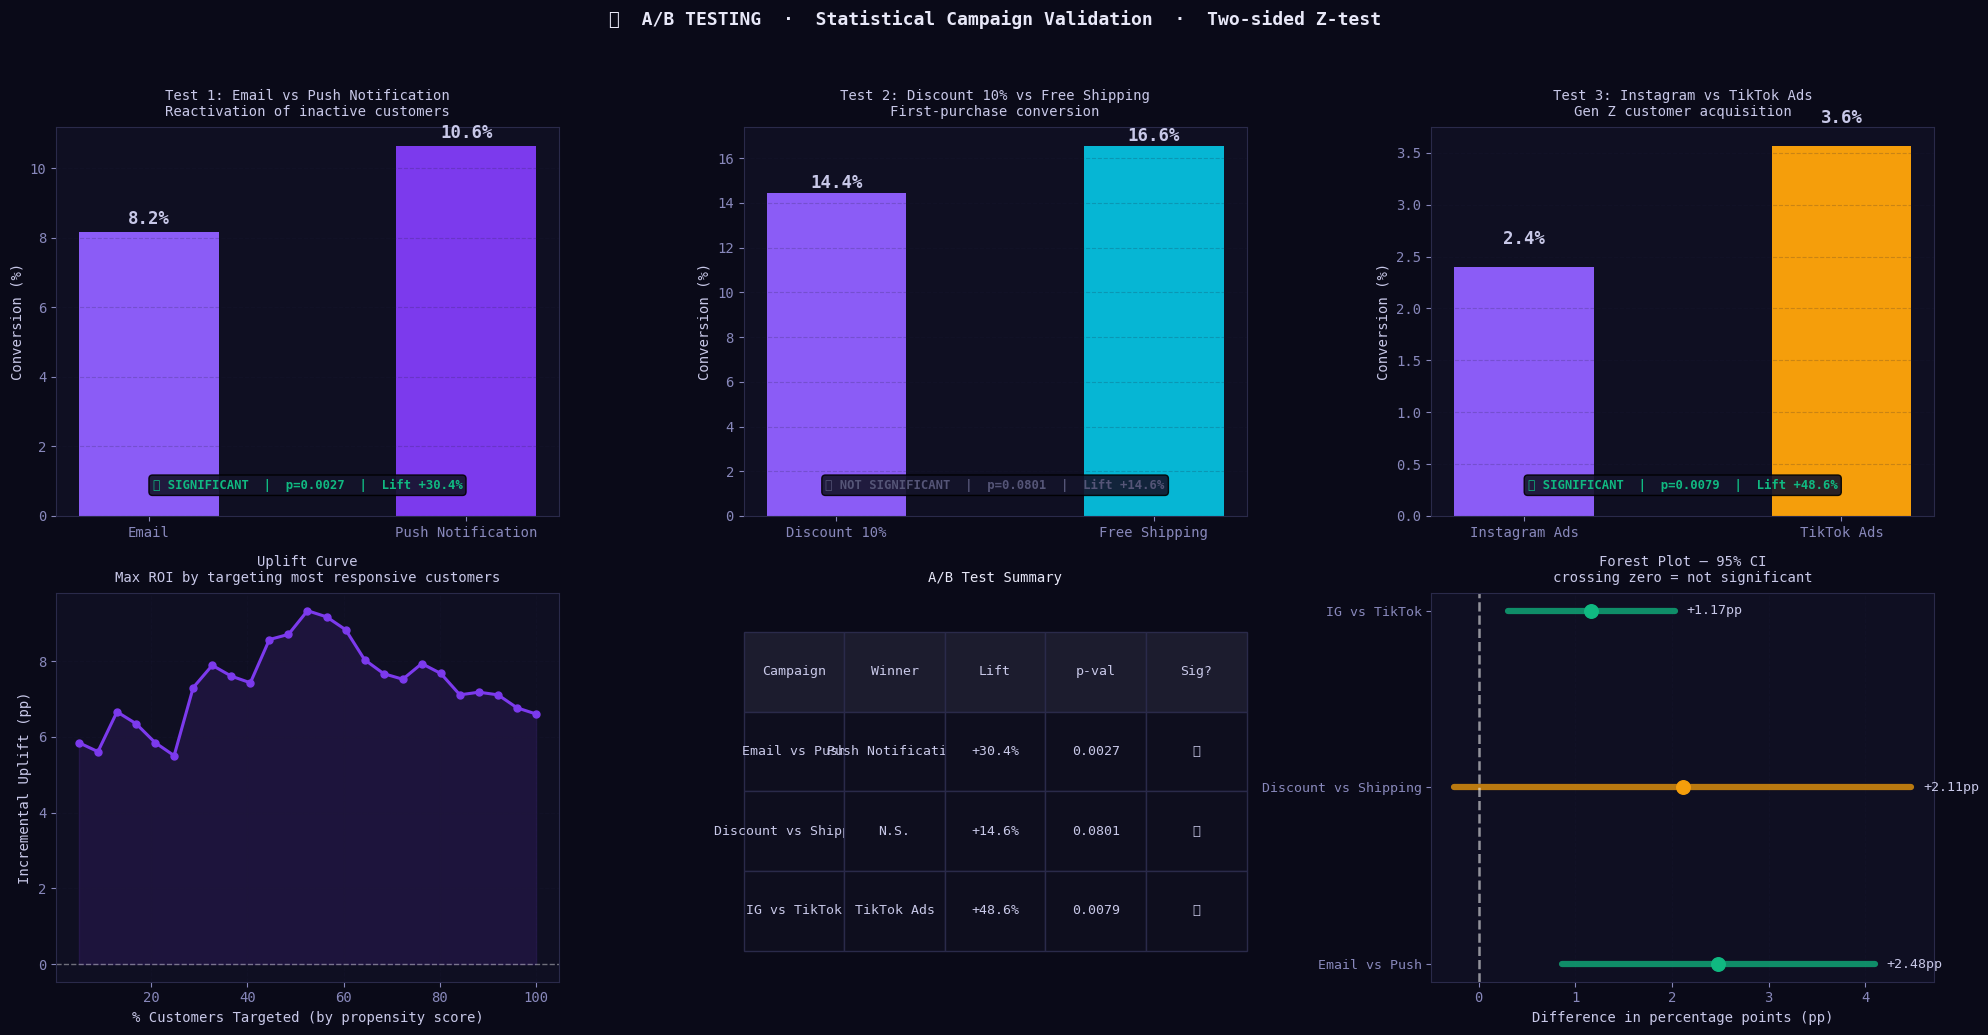

✅ Saved: reports/06_ab_testing.png


In [23]:
# ── Visualisation: A/B Testing (2×3 grid)
fig6, axes6 = plt.subplots(2, 3, figsize=(20, 10))
fig6.suptitle(
    '🧪  A/B TESTING  ·  Statistical Campaign Validation  ·  Two-sided Z-test',
    fontsize=13, fontweight='bold', color='#e8e8f8', y=1.03
)

def plot_ab_bar(ax, t, color_b, title):
    bars = ax.bar([t['lA'],t['lB']], [t['pA']*100,t['pB']*100],
                  color=[PAL[5],color_b], width=0.44, edgecolor='none')
    for bar, v in zip(bars, [t['pA']*100,t['pB']*100]):
        ax.text(bar.get_x()+bar.get_width()/2, v+0.22, f'{v:.1f}%',
                ha='center', fontsize=12.5, fontweight='bold')
    sig = '✅ SIGNIFICANT' if t['significant'] else '⚪ NOT SIGNIFICANT'
    csg = PAL[3] if t['significant'] else '#555577'
    ax.text(0.5, 0.07, f"{sig}  |  p={t['pv']:.4f}  |  Lift {t['lift']:+.1f}%",
            transform=ax.transAxes, ha='center', fontsize=8.8, color=csg, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#14142a', alpha=0.9))
    ax.set_title(title, fontsize=10, pad=8); ax.set_ylabel('Conversion (%)'); ax.grid(True, alpha=0.20, axis='y')

plot_ab_bar(axes6[0,0], t1, PAL[0], 'Test 1: Email vs Push Notification\nReactivation of inactive customers')
plot_ab_bar(axes6[0,1], t2, PAL[1], 'Test 2: Discount 10% vs Free Shipping\nFirst-purchase conversion')
plot_ab_bar(axes6[0,2], t3, PAL[2], 'Test 3: Instagram vs TikTok Ads\nGen Z customer acquisition')

# Uplift Curve
n_up  = 2500; sc_up = np.sort(np.random.uniform(0,1,n_up))[::-1]
tr_up = np.random.binomial(1,0.5,n_up)
cv_up = np.where(tr_up==1, np.random.binomial(1,0.10+sc_up*0.08,n_up), np.random.binomial(1,0.07,n_up))
df_up = pd.DataFrame({'s':sc_up,'t':tr_up,'c':cv_up})
pcts  = np.linspace(0.05,1.0,25); cum_u=[]
for p in pcts:
    top = df_up.iloc[:int(p*n_up)]; tr2=top[top.t==1]; ct2=top[top.t==0]
    cum_u.append(((tr2.c.mean() if len(tr2)>5 else 0)-(ct2.c.mean() if len(ct2)>5 else 0))*100)
axes6[1,0].plot(pcts*100, cum_u, 'o-', color=PAL[0], lw=2.2, ms=5, zorder=3)
axes6[1,0].fill_between(pcts*100, cum_u, 0, where=[u>0 for u in cum_u], alpha=0.13, color=PAL[0])
axes6[1,0].axhline(0, color='white', ls='--', lw=1, alpha=0.4)
axes6[1,0].set_title('Uplift Curve\nMax ROI by targeting most responsive customers', fontsize=10, pad=8)
axes6[1,0].set_xlabel('% Customers Targeted (by propensity score)'); axes6[1,0].set_ylabel('Incremental Uplift (pp)')
axes6[1,0].grid(True, alpha=0.20)

# Summary Table
axes6[1,1].axis('off')
rows = [['Campaign','Winner','Lift','p-val','Sig?']]
for t in tests:
    w = t['lB'] if (t['significant'] and t['lift']>0) else 'N.S.'
    rows.append([t['name'], w, f"{t['lift']:+.1f}%", f"{t['pv']:.4f}", '✅' if t['significant'] else '⚪'])
tbl = axes6[1,1].table(cellText=rows[1:], colLabels=rows[0], cellLoc='center', loc='center', bbox=[0,0.08,1,0.82])
tbl.auto_set_font_size(False); tbl.set_fontsize(9.5)
for (r,c),cell in tbl.get_celld().items():
    cell.set_facecolor('#1c1c2e' if r==0 else '#0e0e1e'); cell.set_edgecolor('#2a2a4a')
    cell.set_text_props(color='#c8c8e8')
axes6[1,1].set_title('A/B Test Summary', fontsize=10, pad=8, color='#e8e8f8')

# Forest Plot
for i, t in enumerate(tests):
    sig_ok = t['ci_lo']>0 or t['ci_hi']<0
    c = PAL[3] if (sig_ok and t['lift']>0) else PAL[4] if (sig_ok and t['lift']<0) else PAL[2]
    diff = (t['pB']-t['pA'])*100
    axes6[1,2].plot([t['ci_lo'],t['ci_hi']], [i,i], color=c, lw=4.5, alpha=0.75, solid_capstyle='round')
    axes6[1,2].scatter([diff],[i], color=c, s=95, zorder=5)
    axes6[1,2].text(max(t['ci_hi'],0)+0.12, i, f'{diff:+.2f}pp', va='center', fontsize=9.5)
axes6[1,2].axvline(0, color='white', ls='--', lw=1.8, alpha=0.55)
axes6[1,2].set_yticks(range(3)); axes6[1,2].set_yticklabels([t['name'] for t in tests], fontsize=9.5)
axes6[1,2].set_title('Forest Plot — 95% CI\ncrossing zero = not significant', fontsize=10, pad=8)
axes6[1,2].set_xlabel('Difference in percentage points (pp)'); axes6[1,2].grid(True, alpha=0.20, axis='x')

plt.tight_layout()
plt.savefig('reports/06_ab_testing.png', dpi=135, bbox_inches='tight', facecolor=DARK_BG)
plt.show()
print("✅ Saved: reports/06_ab_testing.png")

---
## 📊 Section 10 — Executive Dashboard

> 🏷️ **For the business reader:** This is the panel a CEO or CMO would see every morning.  
> All model results transformed into **clear business decisions**:  
> which customers are at risk, how much each segment is worth, what actions to take.

> ⚙️ **For the engineer:**
> - **Priority Score:** $S = 0.6 \times \frac{CLV}{CLV_{max}} + 0.4 \times P(churn)$
> - **Action Matrix:** 4 quadrants {churn × CLV} → 4 distinct CRM actions


In [24]:
# ── Unified scoring for all customers
print("Computing scores for all customers...")
df_score = silver_df[FEATURE_COLS+['customer_id','loyalty_tier','preferred_channel','seg_name']].dropna().copy()
df_score['churn_prob'] = churn_model.predict_proba(df_score[FEATURE_COLS])[:,1]
df_score['clv_12m']    = clv_model.predict(df_score[FEATURE_COLS])

def assign_action(row):
    if row.churn_prob > 0.60 and row.clv_12m > 200: return 'Urgent Retention'
    elif row.clv_12m > 400:                           return 'Nurture VIP'
    elif row.churn_prob > 0.40:                       return 'Reactivation'
    else:                                              return 'Maintenance'

df_score['action']   = df_score.apply(assign_action, axis=1)
df_score['priority'] = ((df_score['clv_12m']/df_score['clv_12m'].max())*0.60 + df_score['churn_prob']*0.40)

TOTAL_C    = len(df_score)
ALTO_RISCO = (df_score.churn_prob>0.60).sum()
VIP_C      = (df_score.clv_12m>400).sum()
PORTFOLIO  = df_score.clv_12m.sum()
URGENTE_C  = (df_score.action=='Urgent Retention').sum()

print(f"\n📊 Portfolio KPIs:")
print(f"   Total customers    : {TOTAL_C:,}")
print(f"   High churn risk    : {ALTO_RISCO:,}  ({ALTO_RISCO/TOTAL_C:.1%})")
print(f"   VIP customers      : {VIP_C:,}  ({VIP_C/TOTAL_C:.1%})")
print(f"   Total CLV 12m      : €{PORTFOLIO:,.0f}")
print(f"   Urgent Retention   : {URGENTE_C:,} customers")

Computing scores for all customers...

📊 Portfolio KPIs:
   Total customers    : 8,000
   High churn risk    : 3,073  (38.4%)
   VIP customers      : 2,975  (37.2%)
   Total CLV 12m      : €3,627,030
   Urgent Retention   : 1,938 customers


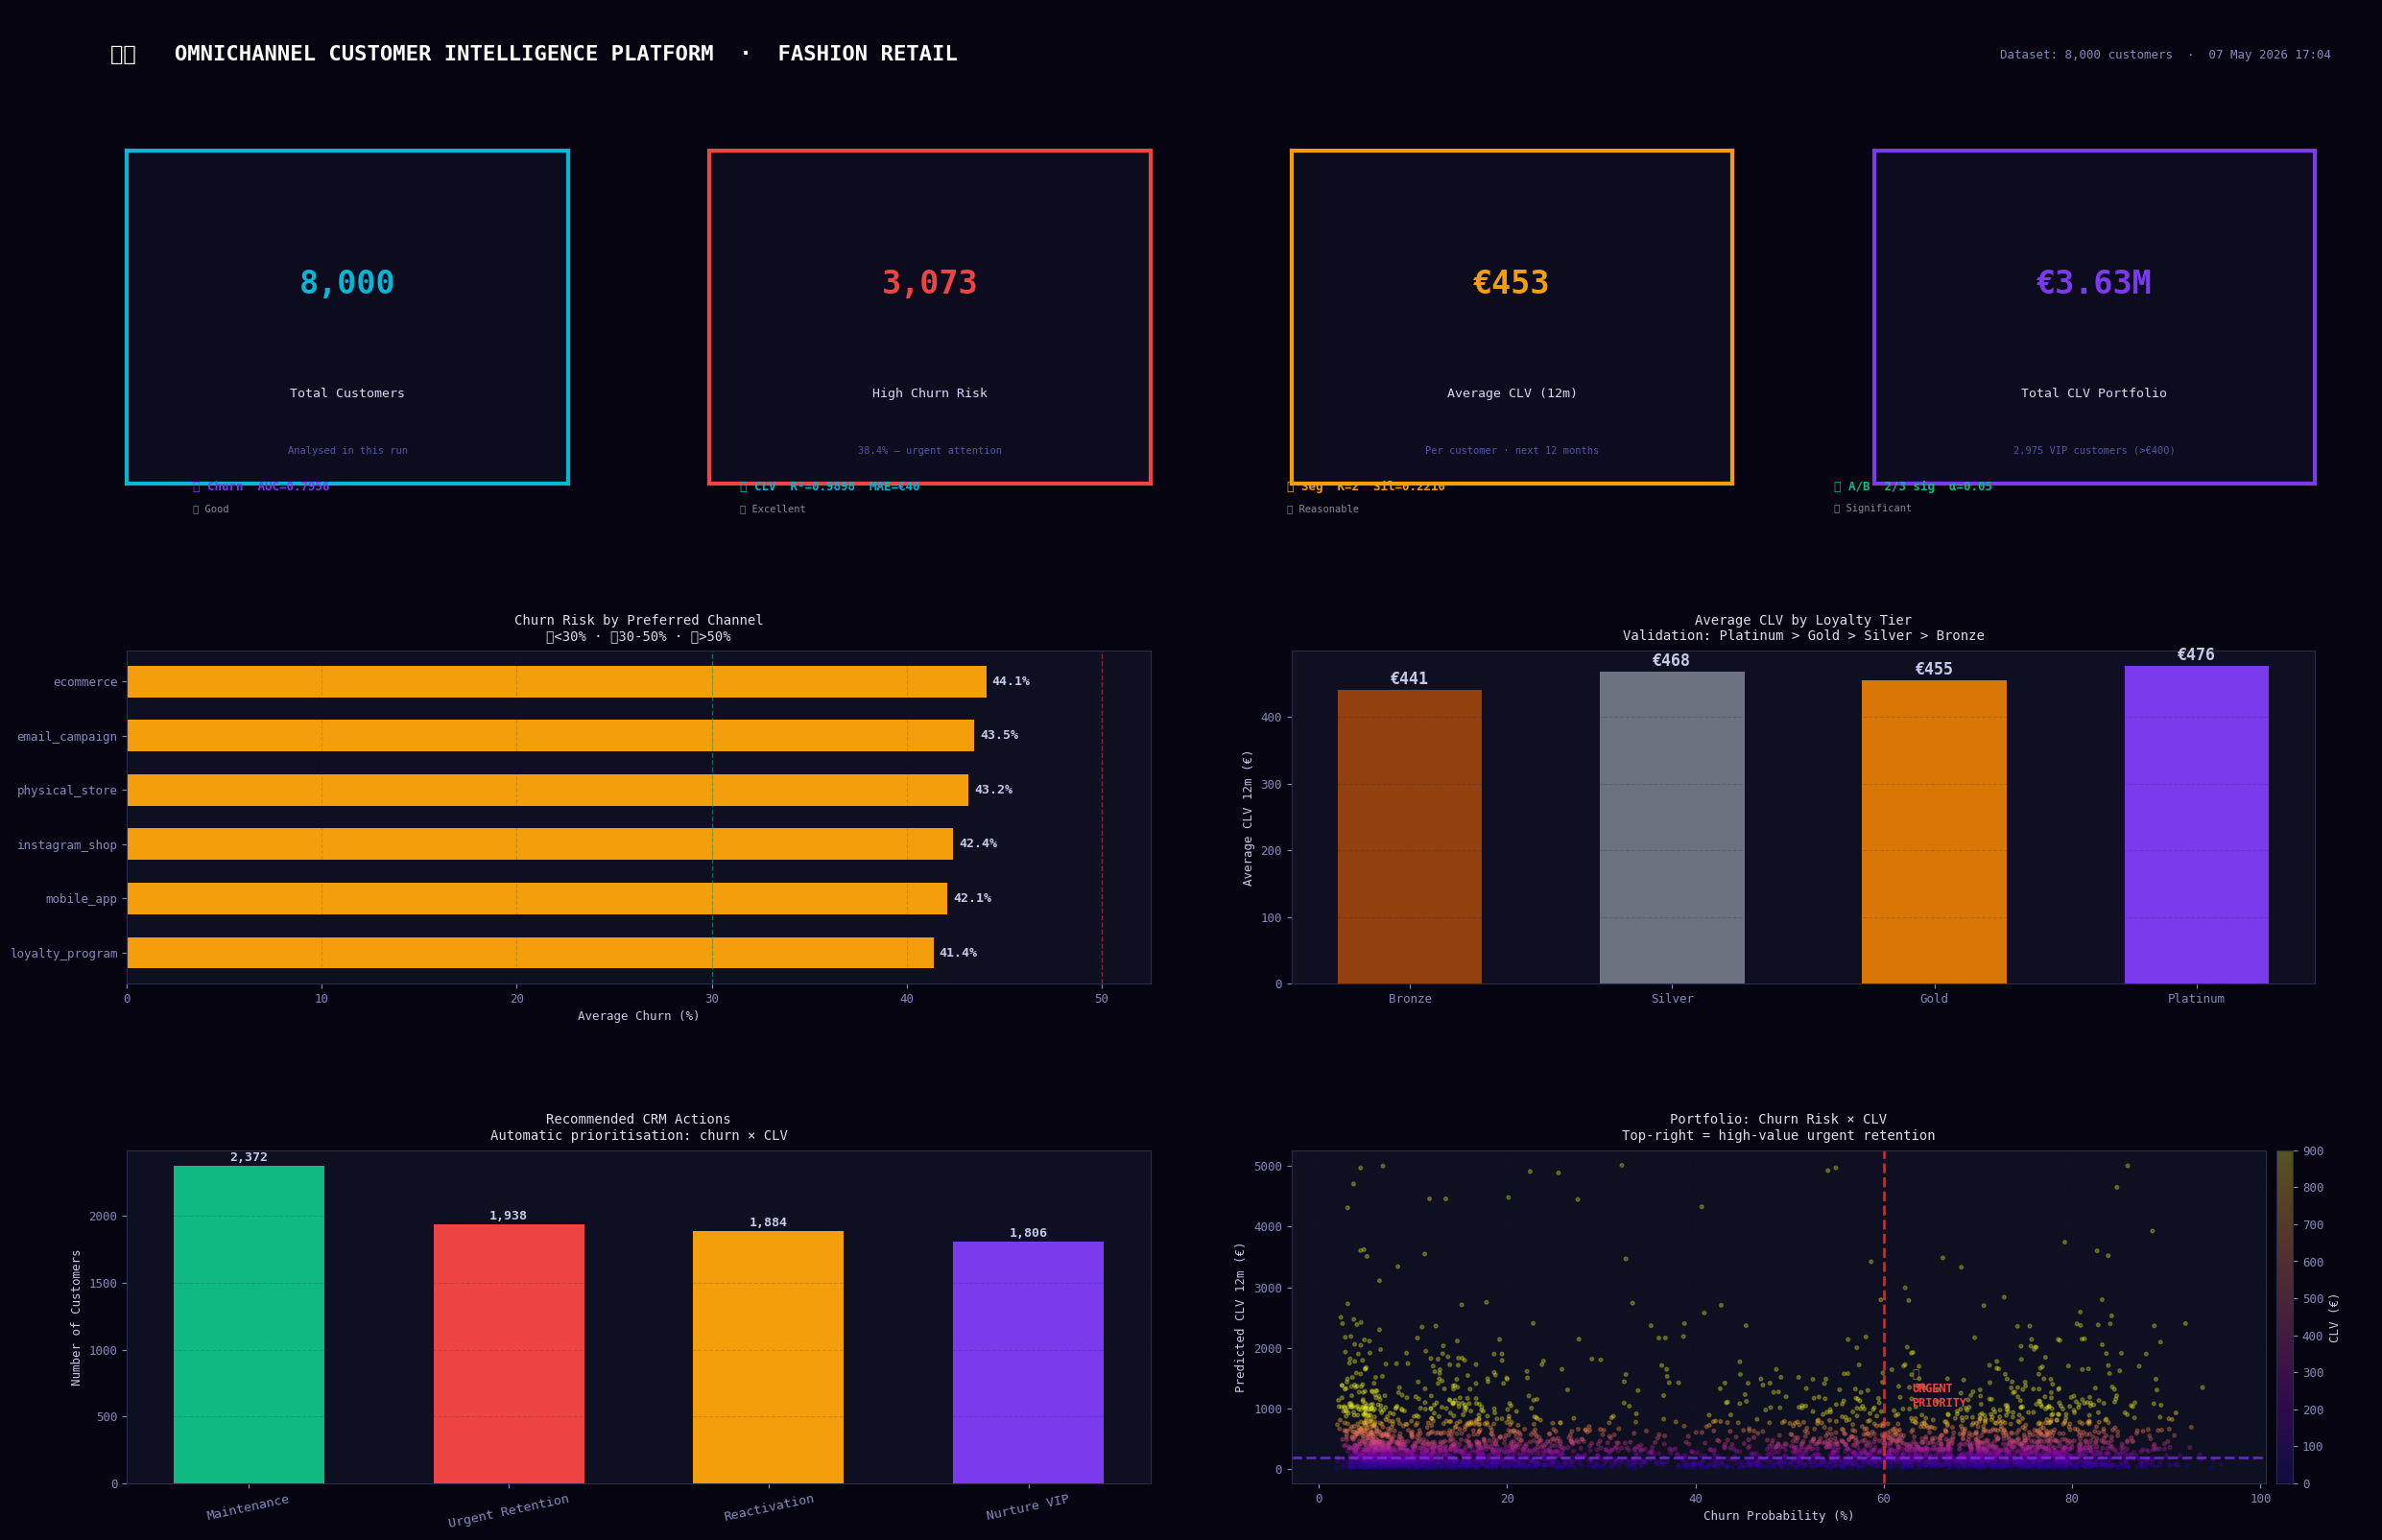

✅ Saved: reports/07_executive_dashboard.png


In [25]:
# ── Executive Dashboard
fig7 = plt.figure(figsize=(24, 16))
fig7.patch.set_facecolor('#050410')

ax_head = fig7.add_axes([0,0.936,1,0.064]); ax_head.set_facecolor('#0e0628')
ax_head.text(0.018,0.54,'🛍️   OMNICHANNEL CUSTOMER INTELLIGENCE PLATFORM  ·  FASHION RETAIL',
             transform=ax_head.transAxes, fontsize=16, color='white', fontweight='bold',
             va='center', family='monospace')
ax_head.text(0.982,0.54,f"Dataset: {TOTAL_C:,} customers  ·  {pd.Timestamp.now().strftime('%d %b %Y %H:%M')}",
             transform=ax_head.transAxes, fontsize=9, color='#8888bb', va='center',
             ha='right', family='monospace')
ax_head.axis('off')
ax_line = fig7.add_axes([0,0.925,1,0.009]); ax_line.set_facecolor('#7c3aed'); ax_line.axis('off')

gs7 = gridspec.GridSpec(3,4,left=0.025,right=0.975,top=0.908,bottom=0.04,hspace=0.50,wspace=0.32)

kpis = [
    ('Total Customers',     f'{TOTAL_C:,}',              PAL[1], 'Analysed in this run'),
    ('High Churn Risk',     f'{ALTO_RISCO:,}',            PAL[4], f'{ALTO_RISCO/TOTAL_C:.1%} — urgent attention'),
    ('Average CLV (12m)',   f'€{df_score.clv_12m.mean():.0f}', PAL[2], 'Per customer · next 12 months'),
    ('Total CLV Portfolio', f'€{PORTFOLIO/1e6:.2f}M',     PAL[0], f'{VIP_C:,} VIP customers (>€400)'),
]
for i,(label,value,color,sub) in enumerate(kpis):
    ax = fig7.add_subplot(gs7[0,i]); ax.set_facecolor('#0c0c1e')
    for sp in ax.spines.values(): sp.set_edgecolor(color); sp.set_linewidth(3.0)
    ax.text(0.5,0.60,value,transform=ax.transAxes,fontsize=24,color=color,ha='center',va='center',fontweight='bold',family='monospace')
    ax.text(0.5,0.27,label,transform=ax.transAxes,fontsize=9.5,color='#d8d8f8',ha='center',va='center')
    ax.text(0.5,0.10,sub,transform=ax.transAxes,fontsize=7.5,color='#5555aa',ha='center',va='center')
    ax.set_xticks([]); ax.set_yticks([])

ax_badge = fig7.add_axes([0.025,0.668,0.950,0.038]); ax_badge.set_facecolor('#0a0a1a')
badges = [
    (f'🤖 Churn  AUC={CHURN_AUC:.4f}','✅ Good' if CHURN_AUC>0.75 else '⚠️',PAL[0]),
    (f'💰 CLV  R²={CLV_R2:.4f}  MAE=€{CLV_MAE:.0f}','✅ Excellent' if CLV_R2>0.90 else '✅ Good',PAL[1]),
    (f'👥 Seg  K={best_k}  Sil={SEG_SIL:.4f}','✅ Reasonable',PAL[2]),
    (f'🧪 A/B  {sum(t["significant"] for t in tests)}/3 sig  α=0.05','✅ Significant',PAL[3]),
]
for i,(txt,status,c) in enumerate(badges):
    x=0.03+i*0.25
    ax_badge.text(x,0.55,txt,transform=ax_badge.transAxes,fontsize=9,color=c,fontweight='bold',va='center',family='monospace')
    ax_badge.text(x,0.18,status,transform=ax_badge.transAxes,fontsize=7.5,color='#888899',va='center',family='monospace')
ax_badge.axis('off')

plt.rcParams.update({'font.size':9})

ax1=fig7.add_subplot(gs7[1,0:2]); ax1.set_facecolor(PANEL_BG)
ch_churn=df_score.groupby('preferred_channel')['churn_prob'].mean().sort_values()
bc1=[PAL[3] if v<0.30 else PAL[2] if v<0.50 else PAL[4] for v in ch_churn.values]
bh1=ax1.barh(ch_churn.index,ch_churn.values*100,color=bc1,edgecolor='none',height=0.58)
for b,v in zip(bh1,ch_churn.values): ax1.text(v*100+0.3,b.get_y()+b.get_height()/2,f'{v:.1%}',va='center',fontsize=9.5,fontweight='bold')
ax1.axvline(30,color=PAL[3],ls='--',lw=1,alpha=0.5); ax1.axvline(50,color=PAL[4],ls='--',lw=1,alpha=0.5)
ax1.set_title('Churn Risk by Preferred Channel\n🟢<30% · 🟡30-50% · 🔴>50%',fontsize=10,pad=8,color='#dde')
ax1.set_xlabel('Average Churn (%)'); ax1.grid(True,alpha=0.18,axis='x')

ax2=fig7.add_subplot(gs7[1,2:4]); ax2.set_facecolor(PANEL_BG)
tier_ord=['Bronze','Silver','Gold','Platinum']; tier_clrs2=['#92400e','#6b7280','#d97706','#7c3aed']
tv={t:df_score[df_score.loyalty_tier==t].clv_12m.mean() for t in tier_ord if (df_score.loyalty_tier==t).any()}
b2=ax2.bar(list(tv.keys()),list(tv.values()),color=tier_clrs2[:len(tv)],width=0.55,edgecolor='none')
for bar,v in zip(b2,tv.values()): ax2.text(bar.get_x()+bar.get_width()/2,v+9,f'€{v:.0f}',ha='center',fontsize=12,fontweight='bold')
ax2.set_title('Average CLV by Loyalty Tier\nValidation: Platinum > Gold > Silver > Bronze',fontsize=10,pad=8,color='#dde')
ax2.set_ylabel('Average CLV 12m (€)'); ax2.grid(True,alpha=0.18,axis='y')

ax3=fig7.add_subplot(gs7[2,0:2]); ax3.set_facecolor(PANEL_BG)
act_c=df_score.action.value_counts()
acm={'Urgent Retention':PAL[4],'Nurture VIP':PAL[0],'Reactivation':PAL[2],'Maintenance':PAL[3]}
bc3=[acm.get(a,PAL[5]) for a in act_c.index]
b3=ax3.bar(range(len(act_c)),act_c.values,color=bc3,edgecolor='none',width=0.58)
ax3.set_xticks(range(len(act_c))); ax3.set_xticklabels(act_c.index,fontsize=9.5,rotation=12)
for bar,v in zip(b3,act_c.values): ax3.text(bar.get_x()+bar.get_width()/2,v+35,f'{v:,}',ha='center',fontsize=9.5,fontweight='bold')
ax3.set_title('Recommended CRM Actions\nAutomatic prioritisation: churn × CLV',fontsize=10,pad=8,color='#dde')
ax3.set_ylabel('Number of Customers'); ax3.grid(True,alpha=0.18,axis='y')

ax4=fig7.add_subplot(gs7[2,2:4]); ax4.set_facecolor(PANEL_BG)
smp7=df_score.sample(min(4000,len(df_score)),random_state=SEED)
sc7=ax4.scatter(smp7.churn_prob*100,smp7.clv_12m,c=smp7.clv_12m,cmap='plasma',alpha=0.30,s=7,vmin=0,vmax=900)
ax4.axvline(60,color=PAL[4],ls='--',lw=2,alpha=0.7); ax4.axhline(200,color=PAL[0],ls='--',lw=2,alpha=0.7)
ax4.text(63,df_score.clv_12m.quantile(0.90),'🚨\nURGENT\nPRIORITY',fontsize=8.5,color=PAL[4],fontweight='bold')
ax4.set_title('Portfolio: Churn Risk × CLV\nTop-right = high-value urgent retention',fontsize=10,pad=8,color='#dde')
ax4.set_xlabel('Churn Probability (%)'); ax4.set_ylabel('Predicted CLV 12m (€)'); ax4.grid(True,alpha=0.18)
plt.colorbar(sc7,ax=ax4,label='CLV (€)',pad=0.01,fraction=0.038)

plt.savefig('reports/07_executive_dashboard.png',dpi=145,bbox_inches='tight',facecolor='#050410')
plt.show()
print("✅ Saved: reports/07_executive_dashboard.png")

---
## 📦 Section 11 — MLflow: Experiment Tracking & Model Registry

> 🏷️ **For the business reader:** MLflow is the scientist's digital lab notebook.  
> Every time we train a model, it automatically records:  
> the recipe used (hyperparameters), the quality score (metrics), and the best version.

> ⚙️ **For the engineer:**
> - `set_experiment()` — isolates runs per business problem (3 distinct experiments)
> - `log_params()` / `log_metrics()` — full traceability for audit
> - `mlflow.xgboost.log_model()` — serialises model with input/output signature
> - In production: use `DagsHub` or `MLflow on Databricks` as remote backend
> - Locally on Colab: `mlflow ui --backend-store-uri mlruns/` → http://localhost:5000


In [27]:
mlflow.set_tracking_uri('mlruns')

# Experiment 1: Churn
mlflow.set_experiment('fashion-churn-prediction')
with mlflow.start_run(run_name='xgboost_churn_v1') as churn_run:
    mlflow.log_params({'model_type':'XGBClassifier','n_estimators':300,'max_depth':5,
                       'learning_rate':0.04,'subsample':0.80,'colsample_bytree':0.80,
                       'n_features':len(FEATURE_COLS),'scale_pos_weight':round(class_weight,4)})
    rpt1 = classification_report(y_test, y_pred, output_dict=True)
    mlflow.log_metrics({'roc_auc':round(CHURN_AUC,4),'pr_auc':round(CHURN_AP,4),
                        'precision_churn':round(rpt1['1']['precision'],4),
                        'recall_churn':round(rpt1['1']['recall'],4),
                        'f1_churn':round(rpt1['1']['f1-score'],4)})
    mlflow.xgboost.log_model(churn_model, 'churn_xgboost')
    churn_run_id = churn_run.info.run_id

# Experiment 2: CLV
mlflow.set_experiment('fashion-clv-prediction')
with mlflow.start_run(run_name='xgboost_clv_v1') as clv_run:
    mlflow.log_params({'model_type':'XGBRegressor','n_estimators':300,'learning_rate':0.04,'max_depth':5})
    mlflow.log_metrics({'r2':round(CLV_R2,4),'mae':round(CLV_MAE,2),'rmse':round(rmse,2)})
    mlflow.xgboost.log_model(clv_model, 'clv_xgboost')
    clv_run_id = clv_run.info.run_id

# Experiment 3: Segmentation
mlflow.set_experiment('fashion-segmentation')
with mlflow.start_run(run_name='kmeans_seg_v1') as seg_run:
    mlflow.log_params({'model_type':'KMeans','n_clusters':best_k,'n_init':15})
    mlflow.log_metrics({'silhouette_score':round(SEG_SIL,4)})
    mlflow.sklearn.log_model(seg_model, 'kmeans_segmentation')
    seg_run_id = seg_run.info.run_id

# Save models locally (joblib — fast inference)
joblib.dump(churn_model,  'models/churn_model.pkl')
joblib.dump(clv_model,    'models/clv_model.pkl')
joblib.dump(seg_model,    'models/seg_model.pkl')
joblib.dump(seg_scaler,   'models/seg_scaler.pkl')
joblib.dump(FEATURE_COLS, 'models/feature_cols.pkl')
joblib.dump({'auc':CHURN_AUC,'ap':CHURN_AP,'r2':CLV_R2,'mae':CLV_MAE,
             'rmse':rmse,'sil':SEG_SIL,'best_k':best_k}, 'models/metrics.pkl')

print("✅ MLflow Tracking — 3 experiments logged:")
print(f"   Churn  run_id: {churn_run_id[:16]}...")
print(f"   CLV    run_id: {clv_run_id[:16]}...")
print(f"   Seg    run_id: {seg_run_id[:16]}...")
print()
print("✅ Models saved (joblib):")
import glob
for f in sorted(glob.glob('models/*.pkl')):
    print(f"   {f:<40} {os.path.getsize(f)/1024:.1f} KB")
print()


2026/05/07 17:10:12 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/07 17:10:20 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/07 17:10:26 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/05/07 17:10:26 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


✅ MLflow Tracking — 3 experiments logged:
   Churn  run_id: b1af8d2a30724746...
   CLV    run_id: 11143bc4512847fa...
   Seg    run_id: 9ef0057b1cab40a7...

✅ Models saved (joblib):
   models/churn_model.pkl                   734.9 KB
   models/clv_model.pkl                     767.4 KB
   models/feature_cols.pkl                  0.5 KB
   models/metrics.pkl                       0.2 KB
   models/seg_model.pkl                     32.1 KB
   models/seg_scaler.pkl                    1.2 KB



In [28]:
import mlflow

client = mlflow.tracking.MlflowClient()
for exp_name in ['fashion-churn-prediction', 'fashion-clv-prediction', 'fashion-segmentation']:
    exp  = client.get_experiment_by_name(exp_name)
    runs = client.search_runs(exp.experiment_id)
    r    = runs[0]
    print(f"\n{exp_name}")
    print(f"  run_id : {r.info.run_id[:16]}...")
    print(f"  metrics: {r.data.metrics}")


fashion-churn-prediction
  run_id : b1af8d2a30724746...
  metrics: {'pr_auc': 0.6108, 'f1_churn': 0.6696, 'recall_churn': 0.8389, 'roc_auc': 0.7956, 'precision_churn': 0.5572}

fashion-clv-prediction
  run_id : 11143bc4512847fa...
  metrics: {'rmse': 52.54, 'r2': 0.9898, 'mae': 40.27}

fashion-segmentation
  run_id : 9ef0057b1cab40a7...
  metrics: {'silhouette_score': 0.221}


---
## 📋 Section 12 — Final Report & Executive Summary

> 🏷️ **For the business reader:** This cell generates the **final Markdown report** —  
> the document that goes to GitHub, to the manager, to the portfolio.  
> Numbers are calculated automatically (no copy-paste).

> ⚙️ **For the engineer:**
> - Report generated **programmatically** with metrics computed in the notebook
> - Eliminates discrepancies between code and documentation
> - Exported in Markdown for compatibility with GitHub Pages, Notion, Confluence


In [29]:
import glob

print()
print('='*66)
print('  🛍️  FASHION INTELLIGENCE PLATFORM — FINAL REPORT')
print('='*66)
print()
print('📊  CUSTOMER BASE')
print(f'   Total analysed        : {TOTAL_C:,}')
print(f'   High churn risk       : {ALTO_RISCO:,} ({ALTO_RISCO/TOTAL_C:.1%})')
print(f'   VIP customers (>€400) : {VIP_C:,} ({VIP_C/TOTAL_C:.1%})')
print(f'   CLV Portfolio (12m)   : €{PORTFOLIO:,.0f}')
print()
print('🤖  MODEL PERFORMANCE')
print(f'   Churn ROC-AUC         : {CHURN_AUC:.4f}  {"✅" if CHURN_AUC>0.75 else "⚠️"}  PR-AUC={CHURN_AP:.4f}')
print(f'   CLV  R²               : {CLV_R2:.4f}  {"✅" if CLV_R2>0.90 else "⚠️"}  MAE=€{CLV_MAE:.2f}')
print(f'   Seg  Silhouette       : {SEG_SIL:.4f}  K={best_k}')
print()
print('🎯  RECOMMENDED CRM ACTIONS')
for action, cnt in df_score.action.value_counts().items():
    emoji = {'Urgent Retention':'🚨','Nurture VIP':'💎','Reactivation':'📧','Maintenance':'✅'}.get(action,'•')
    print(f'   {emoji} {action:<25} : {cnt:,} ({cnt/TOTAL_C:.1%})')
print()
print('🧪  A/B TESTING — RESULTS')
for t in tests:
    w = t["lB"] if t["significant"] else "inconclusive"
    s = "✅" if t["significant"] else "⚪"
    print(f'   {s} {t["name"]:<25} : winner={w} | lift={t["lift"]:+.1f}% | p={t["pv"]:.4f}')
print()
print('🔍  TOP 5 CHURN DRIVERS (XAI/SHAP)')
for i,(_, row) in enumerate(shap_imp_df.head(5).iterrows()):
    print(f'   {i+1}. {row["feature"]:<28} SHAP={row["mean_abs"]:.4f}')
print()
print('📁  GENERATED FILES')
for f in sorted(glob.glob('reports/*.png')+glob.glob('models/*.pkl')):
    print(f'   {f:<46} {os.path.getsize(f)/1024:6.1f} KB')
print()
print('='*66)
print('  ✅ PIPELINE COMPLETE — ready for GitHub + Hugging Face')
print('='*66)


  🛍️  FASHION INTELLIGENCE PLATFORM — FINAL REPORT

📊  CUSTOMER BASE
   Total analysed        : 8,000
   High churn risk       : 3,073 (38.4%)
   VIP customers (>€400) : 2,975 (37.2%)
   CLV Portfolio (12m)   : €3,627,030

🤖  MODEL PERFORMANCE
   Churn ROC-AUC         : 0.7956  ✅  PR-AUC=0.6108
   CLV  R²               : 0.9898  ✅  MAE=€40.27
   Seg  Silhouette       : 0.2210  K=2

🎯  RECOMMENDED CRM ACTIONS
   ✅ Maintenance               : 2,372 (29.6%)
   🚨 Urgent Retention          : 1,938 (24.2%)
   📧 Reactivation              : 1,884 (23.5%)
   💎 Nurture VIP               : 1,806 (22.6%)

🧪  A/B TESTING — RESULTS
   ✅ Email vs Push             : winner=Push Notification | lift=+30.4% | p=0.0027
   ⚪ Discount vs Shipping      : winner=inconclusive | lift=+14.6% | p=0.0801
   ✅ IG vs TikTok              : winner=TikTok Ads | lift=+48.6% | p=0.0079

🔍  TOP 5 CHURN DRIVERS (XAI/SHAP)
   1. Days since purchase          SHAP=0.7241
   2. Support tickets              SHAP=0.3017
   3. R

In [30]:
# ── Generate Markdown report
action_rows = '\n'.join([f'| {a} | {c:,} | {c/TOTAL_C:.1%} |'
                          for a,c in df_score.action.value_counts().items()])
shap_rows = '\n'.join([f'| {i+1} | {row["feature"]} | {row["mean_abs"]:.4f} |'
                        for i,(_, row) in enumerate(shap_imp_df.head(5).iterrows())])

report_md = f"""# 🛍️ Fashion Intelligence Platform — Model Report

*Auto-generated: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M')} UTC*

---

## Executive Summary

| Metric | Value |
|--------|-------|
| Total Customers Analysed | {TOTAL_C:,} |
| High Churn Risk (>60%) | {ALTO_RISCO:,} ({ALTO_RISCO/TOTAL_C:.1%}) |
| VIP Customers (CLV > €400) | {VIP_C:,} ({VIP_C/TOTAL_C:.1%}) |
| Total CLV Portfolio (12m) | €{PORTFOLIO:,.0f} |
| Urgent Retention Actions | {URGENTE_C:,} customers |

---

## Model Performance

### Churn Prediction (XGBoost Classifier)
| Metric | Value |
|--------|-------|
| **ROC-AUC** | **{CHURN_AUC:.4f}** |
| PR-AUC | {CHURN_AP:.4f} |

### CLV Prediction (XGBoost Regressor)
| Metric | Value |
|--------|-------|
| **R²** | **{CLV_R2:.4f}** |
| **MAE** | **€{CLV_MAE:.2f}** |
| RMSE | €{rmse:.2f} |

### Segmentation (KMeans)
| Metric | Value |
|--------|-------|
| Optimal K | {best_k} |
| Silhouette | {SEG_SIL:.4f} |

---

## CRM Actions
| Action | Customers | % of Base |
|--------|-----------|-----------|
{action_rows}

---

## Top 5 Churn Drivers (SHAP)
| # | Feature | mean|SHAP| |
|---|---------|-------------|
{shap_rows}

---

## A/B Testing
| Campaign | Winner | Lift | p-value | Sig? |
|----------|--------|------|---------|------|
{chr(10).join([f"| {t['name']} | {t['lB'] if t['significant'] else 'N.S.'} | {t['lift']:+.1f}% | {t['pv']:.4f} | {'✅' if t['significant'] else '⚪'} |" for t in tests])}

---
*Fashion Intelligence Platform · Senior ML Engineering Project*
"""

os.makedirs('reports', exist_ok=True)
with open('reports/model_report.md','w',encoding='utf-8') as f:
    f.write(report_md)

print("✅ Markdown report: reports/model_report.md")
print()
print("🎉 Fashion Intelligence Platform — 100% complete!")
print()
print("📌 Next steps:")
print("   1. Upload to GitHub repository")
print("   2. GitHub Actions triggers CI/CD automatically on push")
print("   3. Connect MLflow to DagsHub for remote tracking")
print("   4. Deploy dashboard to Hugging Face Spaces (optional)")

✅ Markdown report: reports/model_report.md

🎉 Fashion Intelligence Platform — 100% complete!

📌 Next steps:
   1. Upload to GitHub repository
   2. GitHub Actions triggers CI/CD automatically on push
   3. Connect MLflow to DagsHub for remote tracking
   4. Deploy dashboard to Hugging Face Spaces (optional)


In [31]:
import shutil
shutil.make_archive('/content/fashion_outputs', 'zip', '/content')

from google.colab import files
files.download('/content/fashion_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>